In [3]:
import wandb
from pathlib import Path
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import random

In [4]:
WANDB_API_KEY = "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"
WANDB_TEAM = "24f1001529--dl-genai-project" 
WANDB_PROJECT = "surface-anomaly-segmentation"
wandb.login(key=WANDB_API_KEY)

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin


True

In [5]:
BASE_DIR = Path("/kaggle/input/competitions/industrial-surface-defect-detection/public") 
TRAIN_CSV = BASE_DIR / "train.csv"
SAMPLE_CSV = BASE_DIR / "sample_submission.csv"

TRAIN_IMG_DIR = BASE_DIR / "train"
TEST_IMG_DIR = BASE_DIR / "test"

train_df = pd.read_csv(TRAIN_CSV)
sample_df = pd.read_csv(SAMPLE_CSV)
print("Training annotation shape:", train_df.shape)
print("Test submission template shape:", sample_df.shape)
print("Training columns:", train_df.columns.tolist())
print("Submission columns:", sample_df.columns.tolist())

Training annotation shape: (45572, 5)
Test submission template shape: (12000, 4)
Training columns: ['image_id', 'defect_type', 'mask_rle', 'width', 'height']
Submission columns: ['ID', 'image_id', 'defect_type', 'mask_rle']


# Exploratory Data Analysis

In [6]:
print(train_df.head())
print(sample_df.head())

     image_id defect_type                                           mask_rle  \
0  4S22I7SA34    defect_a  7255 6 7377 12 7505 12 7633 12 7762 11 7890 11...   
1  4S22I7SA34    defect_b                                                NaN   
2  4S22I7SA34    defect_c                                                NaN   
3  4S22I7SA34    defect_d                                                NaN   
4  DZ899111OE    defect_a                                                NaN   

   width  height  
0    800     128  
1    800     128  
2    800     128  
3    800     128  
4    800     128  
   ID    image_id defect_type mask_rle
0   1  WAFNKCRR7Q    defect_a         
1   2  WAFNKCRR7Q    defect_b         
2   3  WAFNKCRR7Q    defect_c         
3   4  WAFNKCRR7Q    defect_d         
4   5  YZXKEWSUDD    defect_a         


In [7]:
print("\nData types:\n", train_df.dtypes)
print("\nMissing values:\n", train_df.isnull().sum())
print("\nDuplicate rows:", train_df.duplicated().sum())
print("Duplicate image/category pairs:",
      train_df.duplicated(["image_id", "defect_type"]).sum())

print("\nUnique image IDs:", train_df["image_id"].nunique())
print("Total annotation rows:", len(train_df))


Data types:
 image_id       object
defect_type    object
mask_rle       object
width           int64
height          int64
dtype: object

Missing values:
 image_id           0
defect_type        0
mask_rle       38371
width              0
height             0
dtype: int64

Duplicate rows: 0
Duplicate image/category pairs: 0

Unique image IDs: 11393
Total annotation rows: 45572


In [8]:
train_df["mask_rle"] = train_df["mask_rle"].fillna("").astype(str).str.strip()
train_df["is_empty"] = train_df["mask_rle"].eq("")

print("\nEmpty masks:", train_df["is_empty"].sum())
print("Non-empty masks:", (~train_df["is_empty"]).sum())


Empty masks: 38371
Non-empty masks: 7201



Category summary:


,annotation_rows,unique_images,empty_masks,nonempty_masks,empty_percent
defect_type,,,,,
defect_a,11393,11393,10312,1081,90.511718
defect_b,11393,11393,11080,313,97.252699
defect_c,11393,11393,7293,4100,64.012990
defect_d,11393,11393,9686,1707,85.017116


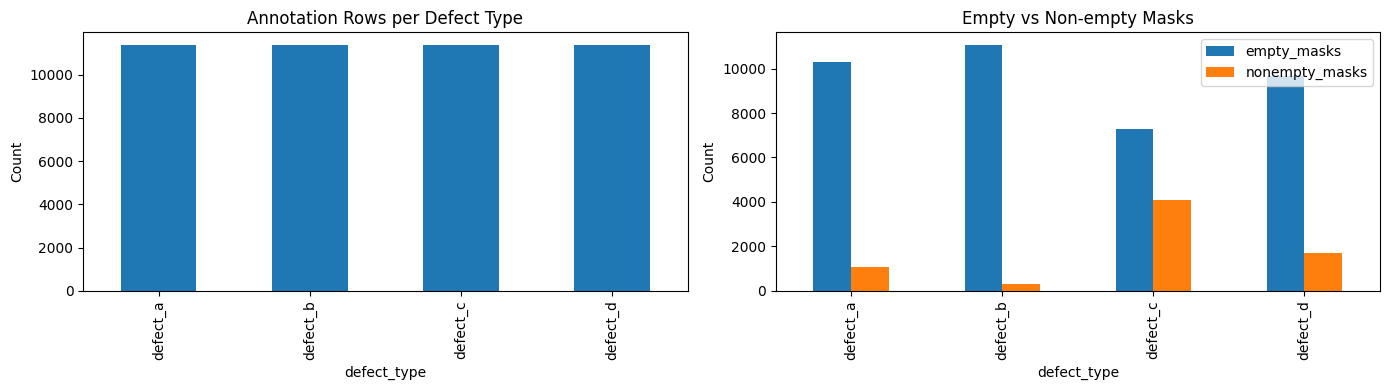

In [9]:
category_summary = train_df.groupby("defect_type").agg(
    annotation_rows=("image_id", "size"),
    unique_images=("image_id", "nunique"),
    empty_masks=("is_empty", "sum")
)
category_summary["nonempty_masks"] = (
    category_summary["annotation_rows"] - category_summary["empty_masks"]
)
category_summary["empty_percent"] = (
    100 * category_summary["empty_masks"] / category_summary["annotation_rows"]
)

print("\nCategory summary:")
display(category_summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
train_df["defect_type"].value_counts().plot(
    kind="bar", ax=axes[0], title="Annotation Rows per Defect Type"
)
category_summary[["empty_masks", "nonempty_masks"]].plot(
    kind="bar", ax=axes[1], title="Empty vs Non-empty Masks"
)
axes[0].set_ylabel("Count")
axes[1].set_ylabel("Count")
plt.tight_layout()
plt.show()

In [10]:
IMAGE_EXTS = {".jpg", ".jpeg", ".png"}
train_images = sorted(
    p for p in TRAIN_IMG_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTS
)
test_images = sorted(
    p for p in TEST_IMG_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTS
)

print("Training image files:", len(train_images))
print("Annotated image IDs:", train_df["image_id"].nunique())
print("Test image files:", len(test_images))
print("Template image IDs:", sample_df["image_id"].nunique())

image_path_map = {p.stem: p for p in train_images}
test_image_ids = {p.stem for p in test_images}

annotated_ids = set(train_df["image_id"].astype(str))
print("Annotated IDs without matching image files:",
      len(annotated_ids - set(image_path_map)))
print("Test image files without template IDs:",
      len(test_image_ids - set(sample_df["image_id"].astype(str))))

Training image files: 11393
Annotated image IDs: 11393
Test image files: 3000
Template image IDs: 3000
Annotated IDs without matching image files: 0
Test image files without template IDs: 0


In [11]:
image_info = []
for path in train_images:
    try:
        with Image.open(path) as img:
            image_info.append({
                "filename": path.name,
                "width": img.width,
                "height": img.height,
                "mode": img.mode
            })
    except Exception as e:
        print("Could not read:", path.name, e)

image_info_df = pd.DataFrame(image_info)

print("\nImage dimensions:")
display(
    image_info_df.groupby(["width", "height"]).size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)
print("\nImage modes:")
display(image_info_df["mode"].value_counts())


Image dimensions:


,width,height,count
0,800,128,11393



Image modes:


mode
RGB    11393
Name: count, dtype: int64

In [12]:
# RLE DECODER - COLUMN-MAJOR ORDER
def decode_rle(mask_rle, height, width):
    mask = np.zeros(height * width, dtype=np.uint8)

    if pd.isna(mask_rle) or str(mask_rle).strip() == "":
        return mask.reshape((height, width), order="F")

    values = np.asarray(str(mask_rle).split(), dtype=np.int64)

    if len(values) % 2 != 0:
        raise ValueError("RLE must contain start-length pairs")

    starts = values[0::2] - 1
    lengths = values[1::2]

    for start, length in zip(starts, lengths):
        if start < 0 or length < 0 or start + length > len(mask):
            raise ValueError("RLE values exceed image dimensions")
        mask[start:start + length] = 1

    return mask.reshape((height, width), order="F")


Mask statistics:


mask_pixels                                                   \
                  count         mean          std  min  25%  50%     75%   
defect_type                                                                
defect_a        11393.0    71.042570   320.887046  0.0  0.0  0.0     0.0   
defect_b        11393.0    18.932766   131.422300  0.0  0.0  0.0     0.0   
defect_c        11393.0  2000.114456  5827.214260  0.0  0.0  0.0  1253.0   
defect_d        11393.0  1071.315194  3599.848723  0.0  0.0  0.0     0.0   

                     coverage_percent                                     \
                 max            count      mean       std  min  25%  50%   
defect_type                                                                
defect_a      7827.0          11393.0  0.069378  0.313366  0.0  0.0  0.0   
defect_b      2992.0          11393.0  0.018489  0.128342  0.0  0.0  0.0   
defect_c     89138.0          11393.0  1.953237  5.690639  0.0  0.0  0.0   
defect_d     50138.0          11393.0  1.046206  3.515477  0.0  0.0  0.0   

                                  
                  75%        max  
defect_type                       
defect_a     0.000000   7.643555  
defect_b     0.000000   2.921875  
defect_c     1.223633  87.048828  
defect_d     0.000000  48.962891

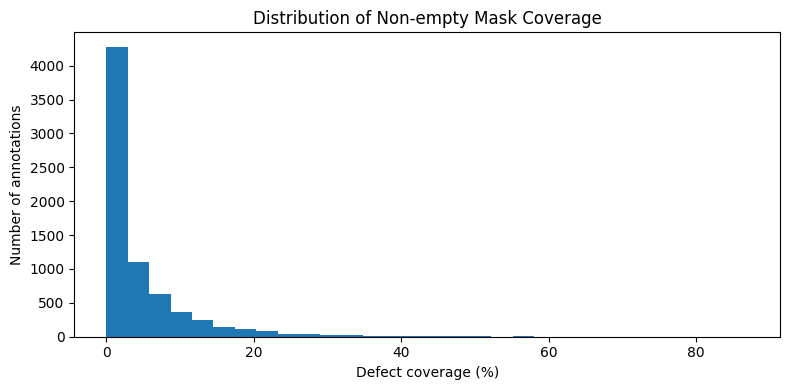

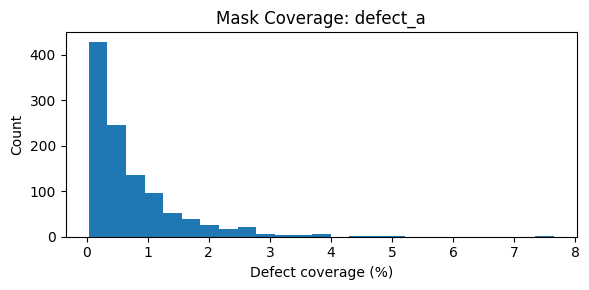

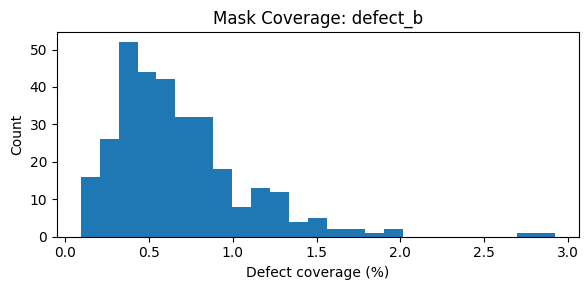

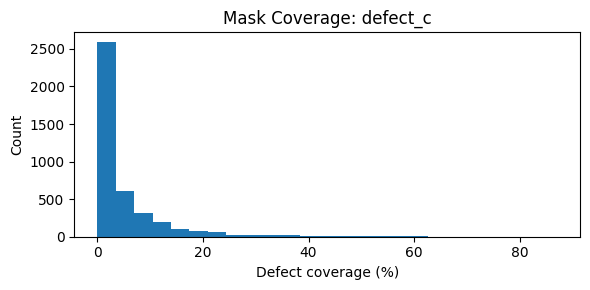

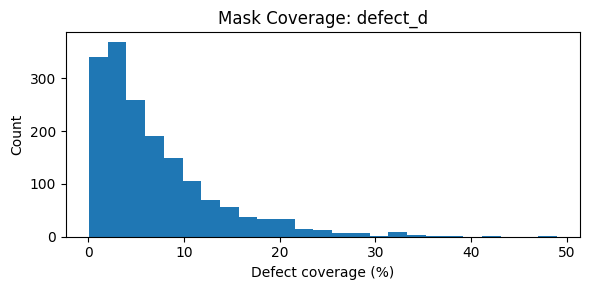

In [13]:
# MASK AREA AND COVERAGE STATISTICS
mask_stats = []

for _, row in train_df.iterrows():
    path = image_path_map.get(str(row["image_id"]))
    if path is None:
        continue

    try:
        with Image.open(path) as img:
            width, height = img.size

        mask = decode_rle(row["mask_rle"], height, width)
        pixels = int(mask.sum())

        mask_stats.append({
            "image_id": row["image_id"],
            "defect_type": row["defect_type"],
            "mask_pixels": pixels,
            "coverage_percent": 100 * pixels / (height * width),
            "is_empty": pixels == 0
        })
    except Exception as e:
        print(f"Mask error for {row['image_id']}: {e}")

mask_stats_df = pd.DataFrame(mask_stats)

print("\nMask statistics:")
if not mask_stats_df.empty:
    display(
        mask_stats_df.groupby("defect_type")[
            ["mask_pixels", "coverage_percent"]
        ].describe()
    )

    positive_coverage = mask_stats_df.loc[
        mask_stats_df["mask_pixels"] > 0, "coverage_percent"
    ]

    plt.figure(figsize=(8, 4))
    plt.hist(positive_coverage, bins=30)
    plt.xlabel("Defect coverage (%)")
    plt.ylabel("Number of annotations")
    plt.title("Distribution of Non-empty Mask Coverage")
    plt.tight_layout()
    plt.show()

    for defect in sorted(mask_stats_df["defect_type"].unique()):
        values = mask_stats_df.loc[
            (mask_stats_df["defect_type"] == defect)
            & (mask_stats_df["mask_pixels"] > 0),
            "coverage_percent"
        ]
        plt.figure(figsize=(6, 3))
        plt.hist(values, bins=25)
        plt.xlabel("Defect coverage (%)")
        plt.ylabel("Count")
        plt.title(f"Mask Coverage: {defect}")
        plt.tight_layout()
        plt.show()

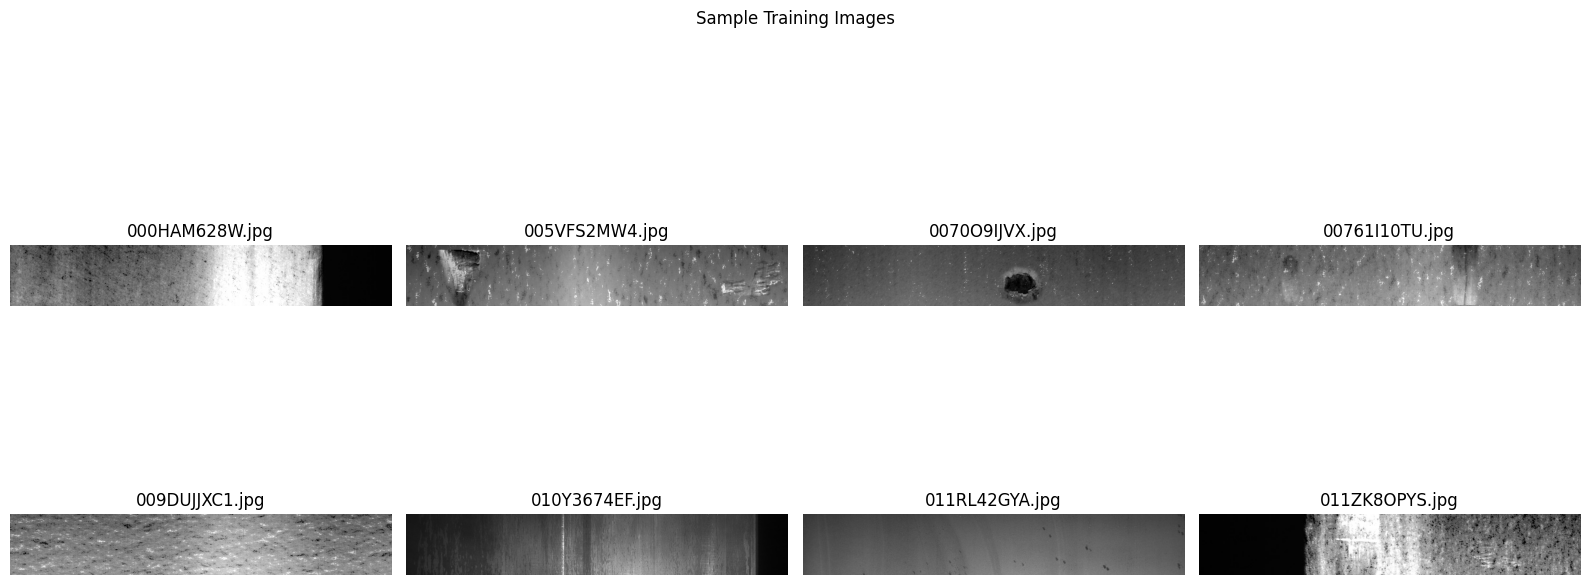

In [14]:
# DISPLAY SAMPLE TRAINING IMAGES
n = min(8, len(train_images))
if n > 0:
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    axes = axes.flatten()

    for ax, path in zip(axes, train_images[:n]):
        with Image.open(path) as img:
            ax.imshow(img.convert("RGB"))
        ax.set_title(path.name)
        ax.axis("off")

    for ax in axes[n:]:
        ax.axis("off")

    plt.suptitle("Sample Training Images")
    plt.tight_layout()
    plt.show()

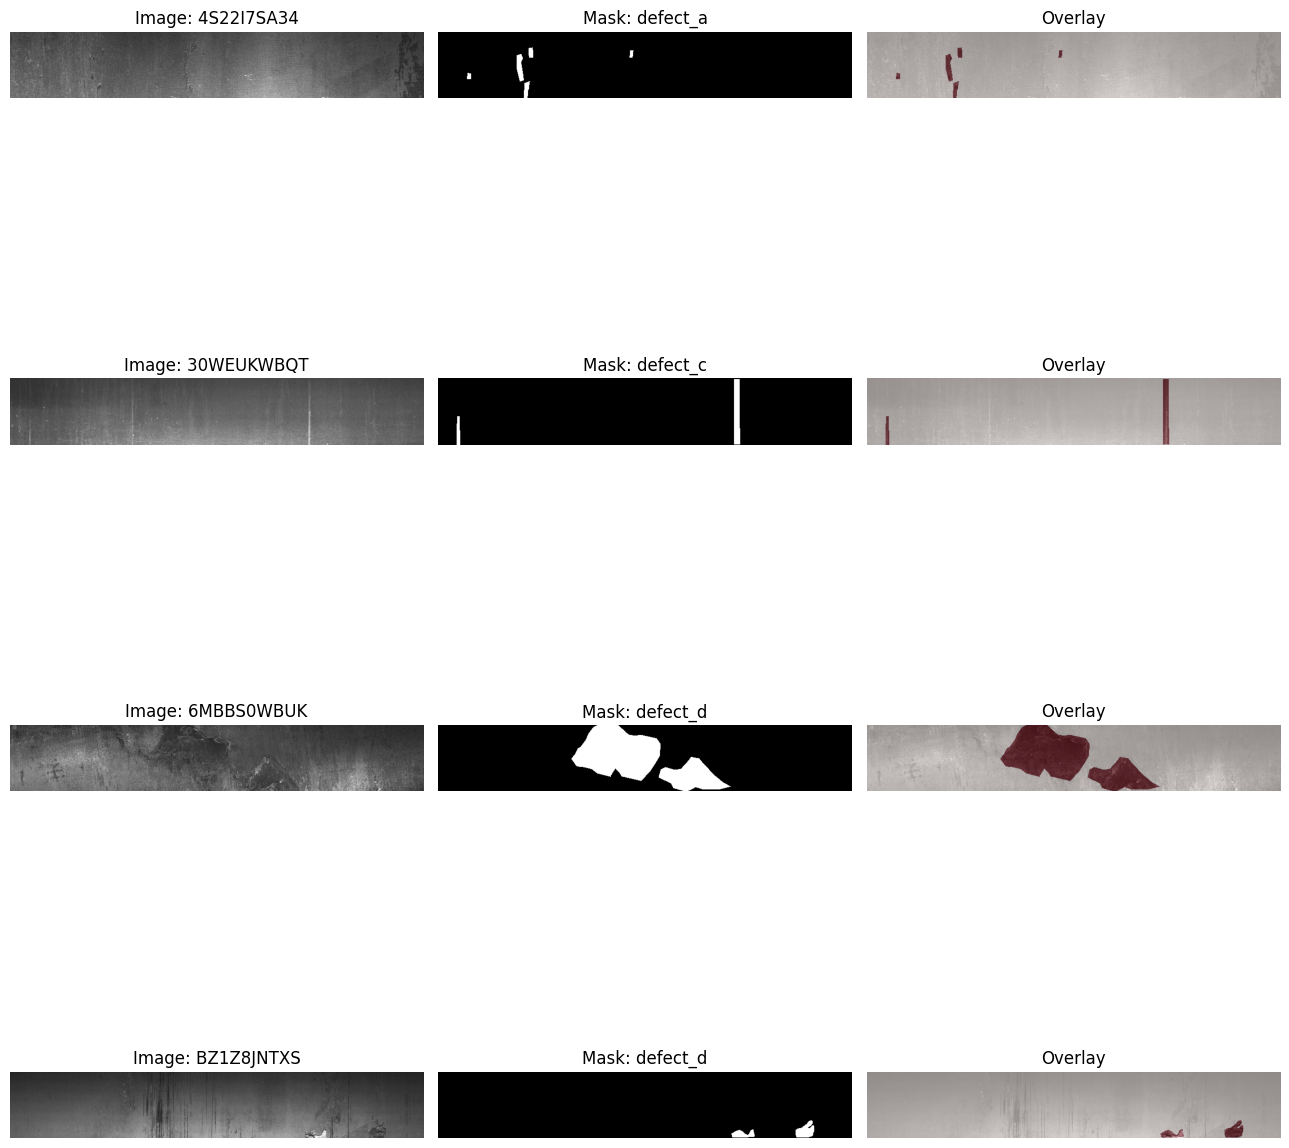

In [15]:
# DISPLAY SAMPLE GROUND-TRUTH MASKS AND OVERLAYS
nonempty = train_df[~train_df["is_empty"]]
n = min(4, len(nonempty))

if n > 0:
    fig, axes = plt.subplots(n, 3, figsize=(13, 4 * n))
    axes = np.atleast_2d(axes)

    shown = 0
    for _, row in nonempty.iterrows():
        path = image_path_map.get(str(row["image_id"]))
        if path is None:
            continue

        with Image.open(path) as img:
            image = np.array(img.convert("RGB"))
            width, height = img.size

        try:
            mask = decode_rle(row["mask_rle"], height, width)
        except ValueError as e:
            print("Skipping invalid mask:", row["image_id"], e)
            continue

        axes[shown, 0].imshow(image)
        axes[shown, 0].set_title(f"Image: {row['image_id']}")
        axes[shown, 1].imshow(mask, cmap="gray", vmin=0, vmax=1)
        axes[shown, 1].set_title(f"Mask: {row['defect_type']}")
        axes[shown, 2].imshow(image)
        axes[shown, 2].imshow(mask, cmap="Reds", alpha=0.5)
        axes[shown, 2].set_title("Overlay")

        for ax in axes[shown]:
            ax.axis("off")

        shown += 1
        if shown == n:
            break

    for i in range(shown, n):
        for ax in axes[i]:
            ax.axis("off")

    plt.tight_layout()
    plt.show()

In [16]:
print("Columns:", sample_df.columns.tolist())
print("Rows:", len(sample_df))
print("Unique image IDs:", sample_df["image_id"].nunique())
print("\nRows per image:")
display(sample_df.groupby("image_id").size().value_counts().sort_index())
print("\nDefect category counts:")
display(sample_df["defect_type"].value_counts())

Columns: ['ID', 'image_id', 'defect_type', 'mask_rle']
Rows: 12000
Unique image IDs: 3000

Rows per image:


4    3000
Name: count, dtype: int64


Defect category counts:


defect_type
defect_a    3000
defect_b    3000
defect_c    3000
defect_d    3000
Name: count, dtype: int64

Defect presence per category:


,positive_images
defect_type,
defect_a,1081
defect_b,313
defect_c,4100
defect_d,1707


Number of images containing each pair of defects:


defect_type,defect_a,defect_b,defect_c,defect_d
defect_type,,,,
defect_a,1081,42,310,234
defect_b,42,313,95,64
defect_c,310,95,4100,705
defect_d,234,64,705,1707


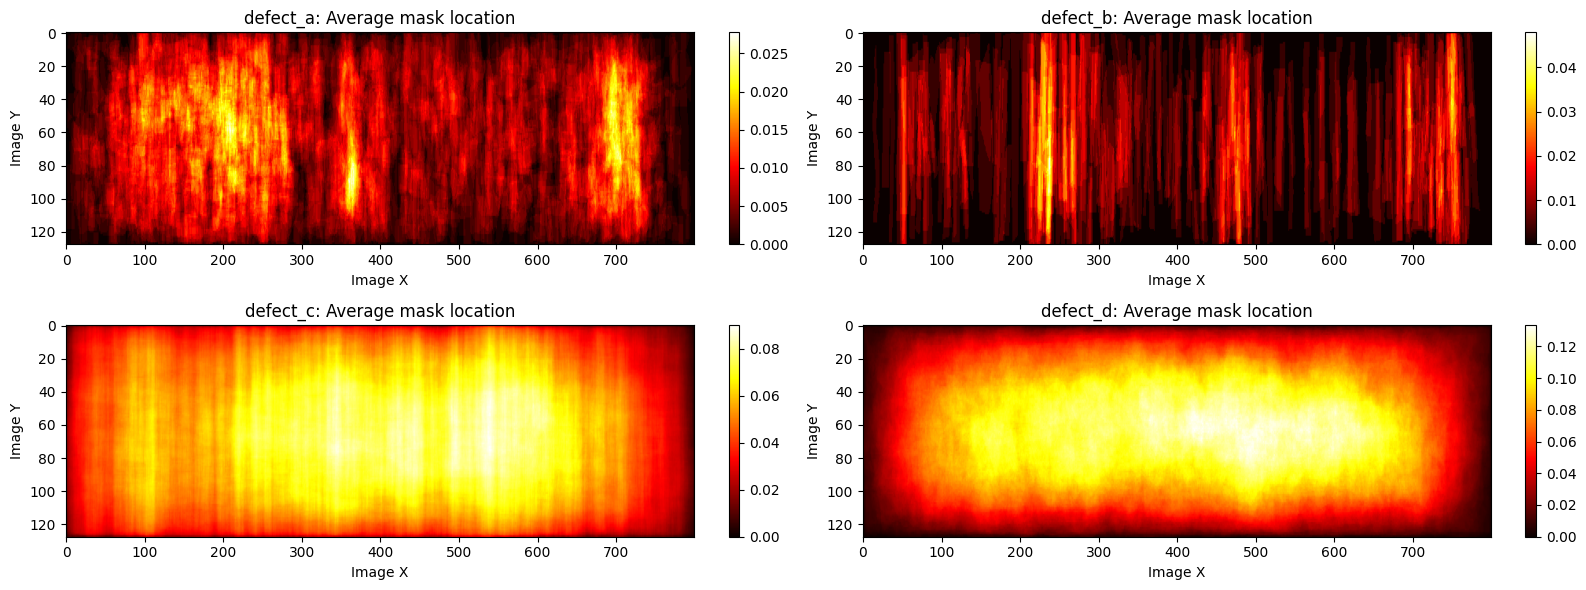

Bounding-box and connected-region statistics:


,area_median,bbox_width_median,bbox_height_median,regions_median,regions_max
defect_type,,,,,
defect_a,472.0,18.0,44.0,1.0,18
defect_b,620.0,11.0,90.0,1.0,3
defect_c,2313.0,96.0,123.0,2.0,73
defect_d,5143.0,120.0,83.0,1.0,27


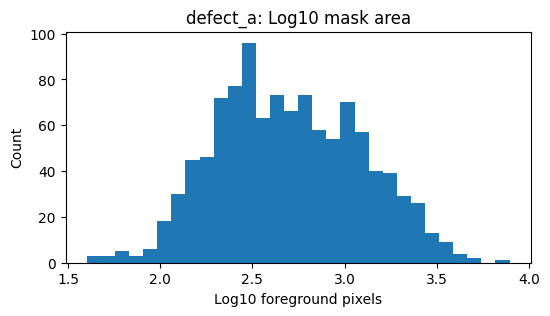

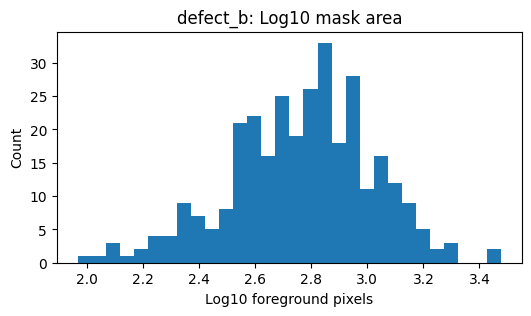

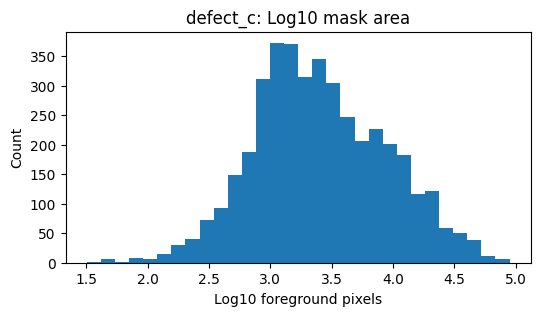

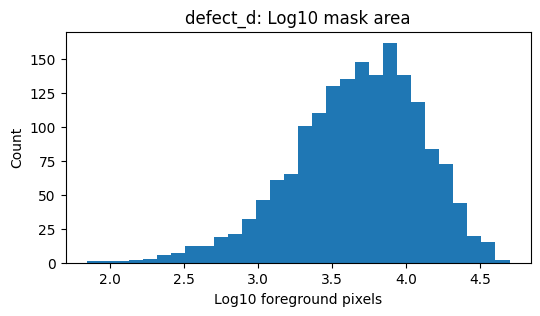

In [17]:

# FURTHER EDA: SPATIAL PATTERNS & CO-OCCURRENCE

import random

DEFECTS = sorted(train_df["defect_type"].unique())

# 1. Which defect categories occur together?
presence = (
    train_df.assign(
        has_defect=train_df["mask_rle"].fillna("").astype(str).str.strip().ne("")
    )
    .pivot(index="image_id", columns="defect_type", values="has_defect")
    .fillna(False)
    .astype(int)
)

print("Defect presence per category:")
display(presence.sum().to_frame("positive_images"))

print("Number of images containing each pair of defects:")
display(presence.T.dot(presence))

# 2. Spatial heatmaps of positive mask pixels
# Each heatmap shows where defects tend to occur across the image.
spatial_maps = {
    defect: np.zeros((128, 800), dtype=np.float64)
    for defect in DEFECTS
}
positive_counts = {defect: 0 for defect in DEFECTS}

for _, row in train_df.iterrows():
    rle = row["mask_rle"]
    if pd.isna(rle) or not str(rle).strip():
        continue

    path = image_path_map.get(str(row["image_id"]))
    if path is None:
        continue

    mask = decode_rle(rle, int(row["height"]), int(row["width"]))

    if mask.shape != (128, 800):
        mask = np.array(
            Image.fromarray(mask).resize((800, 128), resample=Image.Resampling.NEAREST)
        )

    spatial_maps[row["defect_type"]] += mask
    positive_counts[row["defect_type"]] += 1

fig, axes = plt.subplots(2, 2, figsize=(16, 6))

for ax, defect in zip(axes.flat, DEFECTS):
    if positive_counts[defect] > 0:
        heatmap = spatial_maps[defect] / positive_counts[defect]
        im = ax.imshow(heatmap, cmap="hot", aspect="auto")
        ax.set_title(f"{defect}: Average mask location")
        ax.set_xlabel("Image X")
        ax.set_ylabel("Image Y")
        plt.colorbar(im, ax=ax, fraction=0.03)

plt.tight_layout()
plt.show()

# 3. Defect bounding boxes and approximate connected-region counts
try:
    from scipy.ndimage import label

    region_stats = []

    for _, row in train_df[train_df["mask_rle"].fillna("").astype(str).str.strip().ne("")].iterrows():
        path = image_path_map.get(str(row["image_id"]))
        if path is None:
            continue

        mask = decode_rle(row["mask_rle"], int(row["height"]), int(row["width"]))
        ys, xs = np.where(mask > 0)

        if len(xs) == 0:
            continue

        _, n_components = label(mask)

        region_stats.append({
            "defect_type": row["defect_type"],
            "area_pixels": int(mask.sum()),
            "bbox_width": int(xs.max() - xs.min() + 1),
            "bbox_height": int(ys.max() - ys.min() + 1),
            "connected_regions": int(n_components)
        })

    region_df = pd.DataFrame(region_stats)

    print("Bounding-box and connected-region statistics:")
    display(region_df.groupby("defect_type").agg(
        area_median=("area_pixels", "median"),
        bbox_width_median=("bbox_width", "median"),
        bbox_height_median=("bbox_height", "median"),
        regions_median=("connected_regions", "median"),
        regions_max=("connected_regions", "max")
    ))

    for defect in DEFECTS:
        vals = region_df.loc[
            region_df["defect_type"] == defect, "area_pixels"
        ]
        plt.figure(figsize=(6, 3))
        plt.hist(np.log10(vals.clip(lower=1)), bins=30)
        plt.title(f"{defect}: Log10 mask area")
        plt.xlabel("Log10 foreground pixels")
        plt.ylabel("Count")
        plt.show()

except ImportError:
    print("Install scipy to calculate connected-region statistics.")


defect_a: brightness and contrast


mean_brightness                                  contrast_std  \
                         count       mean     median        std        count   
defect_a                                                                       
Defect present              44  77.784746  81.656811  25.909409           44   
Mask empty                 456  88.976304  93.972988  31.178341          456   

                                                 
                     mean     median        std  
defect_a                                         
Defect present  37.550984  35.090883  14.202190  
Mask empty      34.046517  30.418202  15.077949

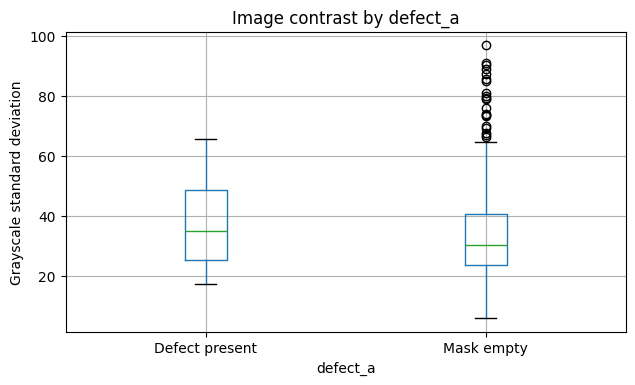


defect_b: brightness and contrast


mean_brightness                                  contrast_std  \
                         count       mean     median        std        count   
defect_b                                                                       
Defect present              15  61.132597  70.945412  37.490694           15   
Mask empty                 485  88.822133  93.238632  30.334191          485   

                                                 
                     mean     median        std  
defect_b                                         
Defect present  39.975284  39.528362  19.570155  
Mask empty      34.181084  30.822752  14.851707

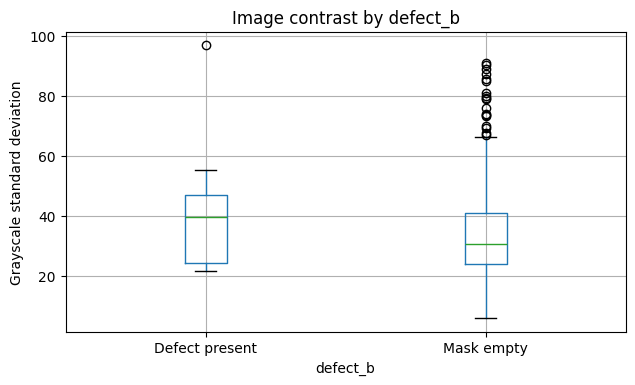


defect_c: brightness and contrast


mean_brightness                                  contrast_std  \
                         count       mean     median        std        count   
defect_c                                                                       
Defect present             182  86.978493  91.458778  31.404336          182   
Mask empty                 318  88.571187  93.207138  30.629085          318   

                                                 
                     mean     median        std  
defect_c                                         
Defect present  37.999071  35.891710  14.897054  
Mask empty      32.269258  28.580056  14.714919

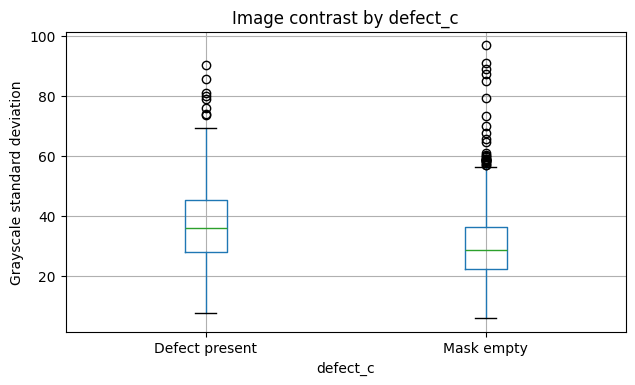


defect_d: brightness and contrast


mean_brightness                                  contrast_std  \
                         count       mean     median        std        count   
defect_d                                                                       
Defect present              77  91.052531  91.173454  29.991171           77   
Mask empty                 423  87.434228  93.064056  31.054903          423   

                                                 
                     mean     median        std  
defect_d                                         
Defect present  37.338685  33.450668  16.243488  
Mask empty      33.811765  30.199841  14.744652

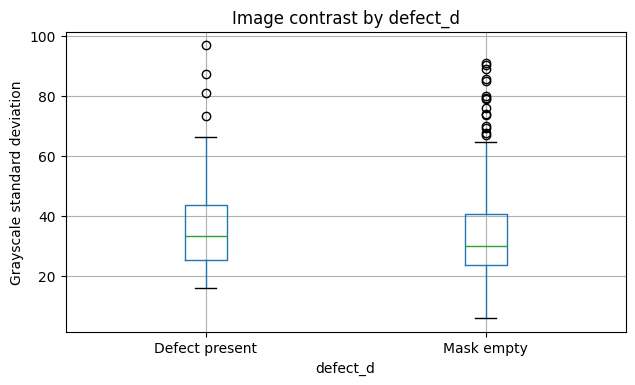

In [18]:

# IMAGE APPEARANCE
rng = np.random.default_rng(42)
sample_ids = rng.choice(
    train_df["image_id"].unique(),
    size=min(500, train_df["image_id"].nunique()),
    replace=False
)

appearance = []

for image_id in sample_ids:
    path = image_path_map.get(str(image_id))
    if path is None:
        continue

    with Image.open(path) as img:
        gray = np.asarray(img.convert("L"), dtype=np.float32)

    row = {
        "image_id": image_id,
        "mean_brightness": float(gray.mean()),
        "contrast_std": float(gray.std())
    }

    for defect in DEFECTS:
        mask_row = train_df[
            (train_df["image_id"] == image_id)
            & (train_df["defect_type"] == defect)
        ]

        row[defect] = (
            len(mask_row) > 0
            and mask_row["mask_rle"].fillna("").astype(str).str.strip().ne("").any()
        )

    appearance.append(row)

appearance_df = pd.DataFrame(appearance)

for defect in DEFECTS:
    appearance_df[defect] = appearance_df[defect].map({
        True: "Defect present",
        False: "Mask empty"
    })

    print(f"\n{defect}: brightness and contrast")
    display(
        appearance_df.groupby(defect)[
            ["mean_brightness", "contrast_std"]
        ].agg(["count", "mean", "median", "std"])
    )

    appearance_df.boxplot(
        column="contrast_std",
        by=defect,
        figsize=(7, 4)
    )
    plt.title(f"Image contrast by {defect}")
    plt.suptitle("")
    plt.ylabel("Grayscale standard deviation")
    plt.show()


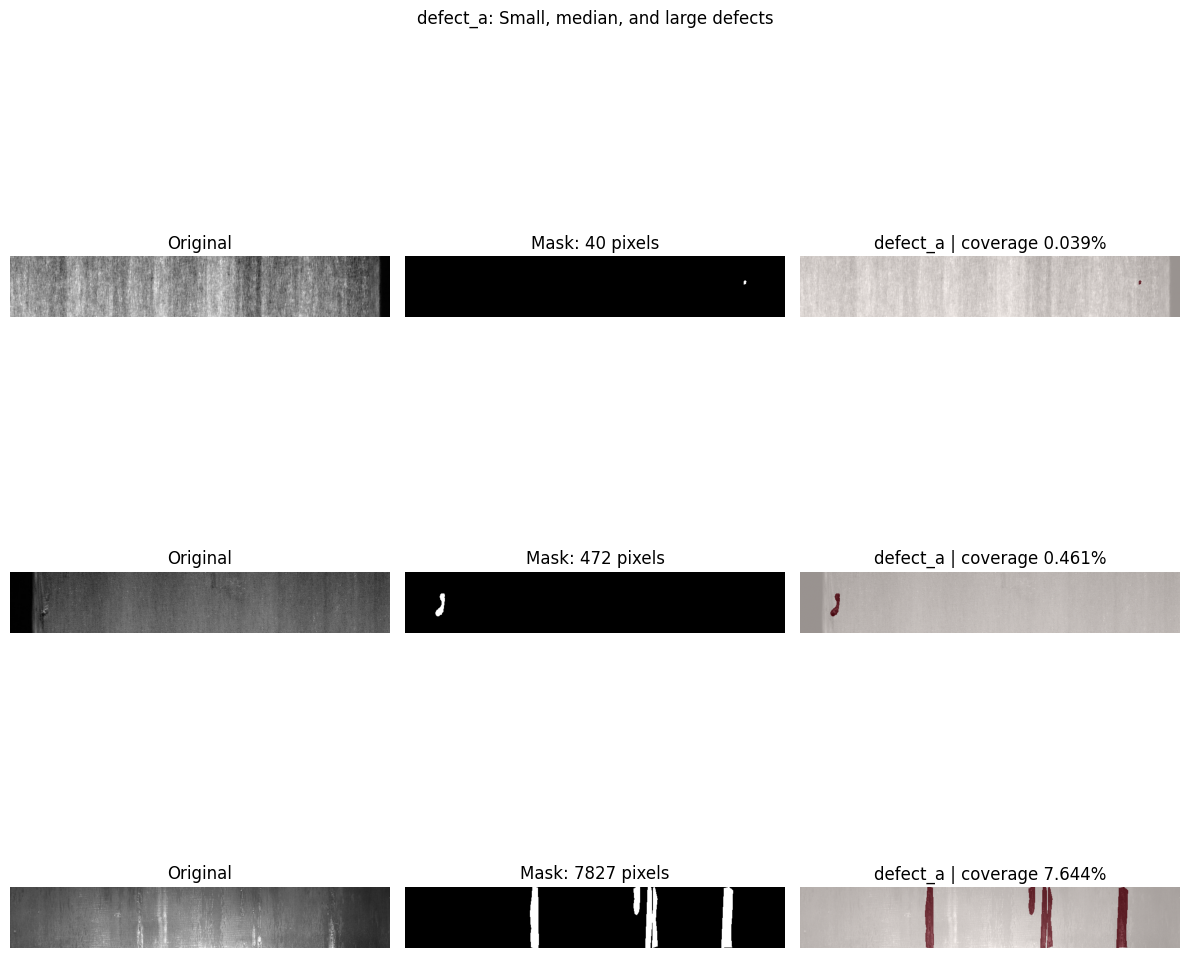

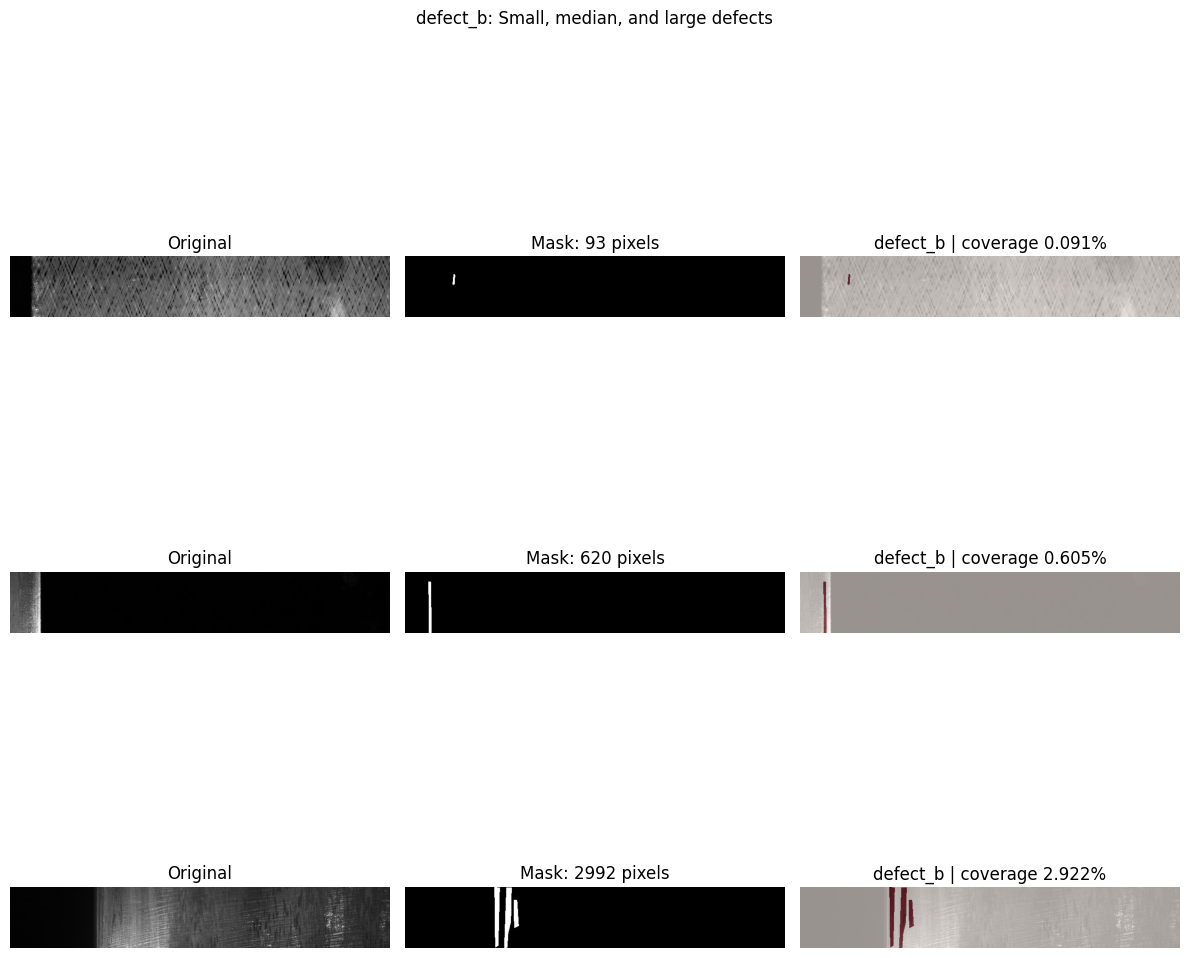

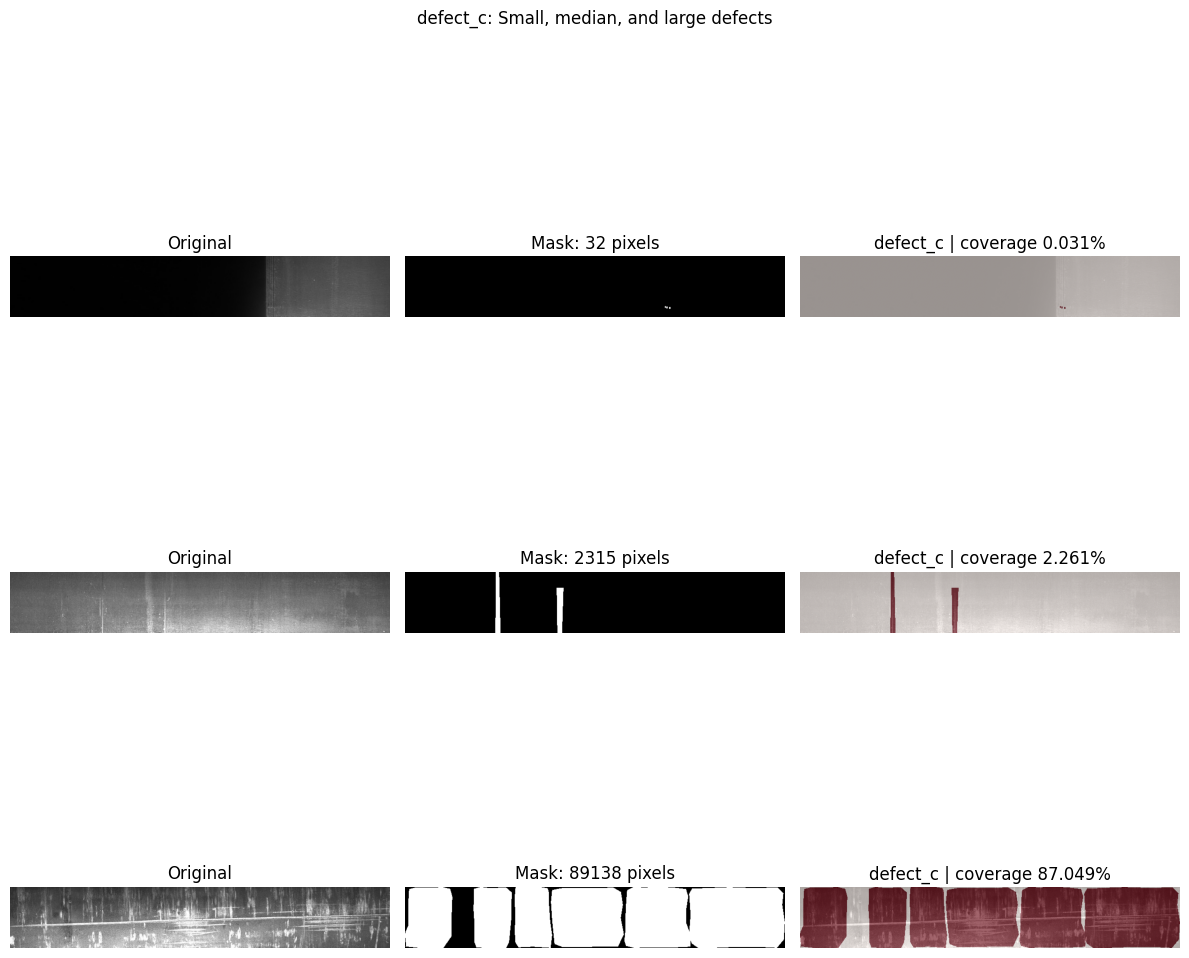

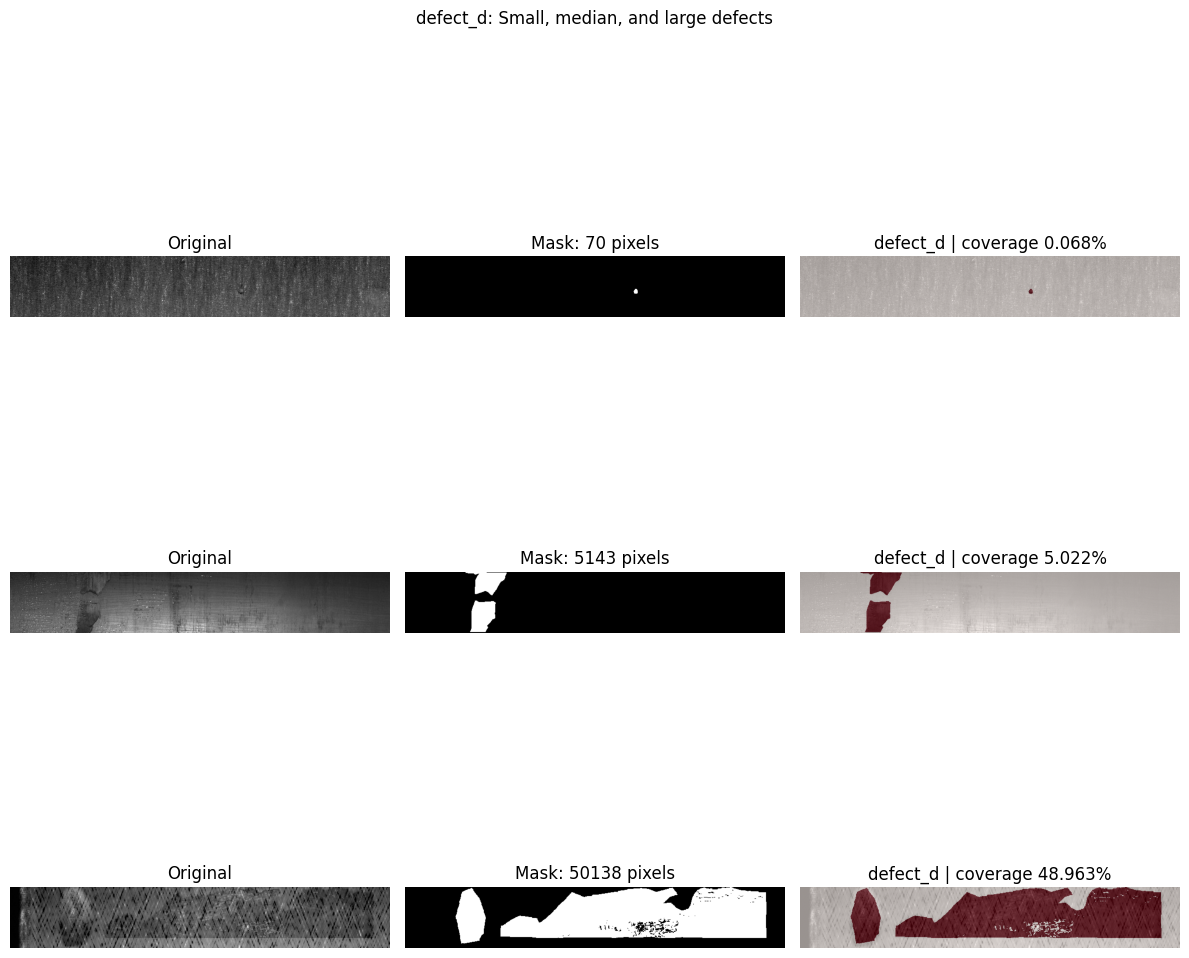

RLE area consistency check:


,positive_masks,minimum_positive_area,median_positive_area,maximum_area
defect_type,,,,
defect_a,1081.0,40.0,472.0,7827.0
defect_b,313.0,93.0,620.0,2992.0
defect_c,4100.0,32.0,2313.0,89138.0
defect_d,1707.0,70.0,5143.0,50138.0


In [19]:

# DEFECT DIFFICULTY 
for defect in sorted(train_df["defect_type"].unique()):
    stats = mask_stats_df[
        (mask_stats_df["defect_type"] == defect)
        & (mask_stats_df["mask_pixels"] > 0)
    ].sort_values("mask_pixels")

    if stats.empty:
        continue

    # Smallest, median-sized, and largest positive masks
    selected = stats.iloc[
        sorted(set([0, len(stats) // 2, len(stats) - 1]))
    ]

    fig, axes = plt.subplots(len(selected), 3, figsize=(12, 4 * len(selected)))
    axes = np.atleast_2d(axes)

    for i, (_, stat) in enumerate(selected.iterrows()):
        row = train_df[
            (train_df["image_id"] == stat["image_id"])
            & (train_df["defect_type"] == defect)
        ].iloc[0]

        path = image_path_map.get(str(row["image_id"]))
        if path is None:
            continue

        with Image.open(path) as img:
            image = np.array(img.convert("RGB"))
            width, height = img.size

        mask = decode_rle(row["mask_rle"], height, width)

        axes[i, 0].imshow(image)
        axes[i, 0].set_title("Original")

        axes[i, 1].imshow(mask, cmap="gray", vmin=0, vmax=1)
        axes[i, 1].set_title(f"Mask: {int(mask.sum())} pixels")

        axes[i, 2].imshow(image)
        axes[i, 2].imshow(mask, cmap="Reds", alpha=0.6)
        axes[i, 2].set_title(
            f"{defect} | coverage {100 * mask.mean():.3f}%"
        )

        for ax in axes[i]:
            ax.axis("off")

    plt.suptitle(f"{defect}: Small, median, and large defects")
    plt.tight_layout()
    plt.show()

# Verify that positive-mask area is consistent with RLE run lengths
def rle_pixel_count(rle):
    if pd.isna(rle) or not str(rle).strip():
        return 0
    values = np.asarray(str(rle).split(), dtype=np.int64)
    return int(values[1::2].sum())

train_df["rle_pixel_count"] = train_df["mask_rle"].apply(rle_pixel_count)

print("RLE area consistency check:")
display(
    train_df.groupby("defect_type").apply(
        lambda g: pd.Series({
            "positive_masks": int((g["rle_pixel_count"] > 0).sum()),
            "minimum_positive_area": int(
                g.loc[g["rle_pixel_count"] > 0, "rle_pixel_count"].min()
            ),
            "median_positive_area": float(
                g.loc[g["rle_pixel_count"] > 0, "rle_pixel_count"].median()
            ),
            "maximum_area": int(g["rle_pixel_count"].max())
        }),
        include_groups=False
    )
)


# Milestone 1

In [20]:
!pip install segmentation_models_pytorch -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 3.5 MB/s eta 0:00:0000:01


In [21]:
df = train_df.copy()
df["pos"] = df["mask_rle"].fillna("").astype(str).str.strip().ne("")
per_class = df.groupby("defect_type")["pos"].sum()
per_image = df.groupby("image_id")["pos"].sum()
clean = int((per_image == 0).sum())
print(per_class.to_dict(), "| clean:", clean)
print("Q1 answer:", int(per_class.max()) + clean)

{'defect_a': 1081, 'defect_b': 313, 'defect_c': 4100, 'defect_d': 1707} | clean: 5516
Q1 answer: 9616


In [22]:
df = train_df.copy()
df["pos"] = df["mask_rle"].fillna("").astype(str).str.strip().ne("")
per_image = df.groupby("image_id")["pos"].sum()
print("Q2 answer:", int((per_image > 1).sum()))

Q2 answer: 1198


In [23]:
import numpy as np
H, W = 128, 800
N = H * W
df = train_df.copy()
df["mask_rle"] = df["mask_rle"].fillna("").astype(str).str.strip()
df["pos"] = df["mask_rle"].ne("")
per_image = df.groupby("image_id")["pos"].sum()
multi_ids = per_image[per_image > 1].index

def decode_clip(rle):
    m = np.zeros(N, dtype=np.uint8)
    v = np.array(rle.split(), dtype=np.int64)
    for s, l in zip(v[0::2] - 1, v[1::2]):
        s0, e0 = max(s, 0), min(s + l, N)
        if e0 > s0:
            m[s0:e0] = 1
    return m.reshape((H, W), order="F")

total = 0
sub = df[df.image_id.isin(multi_ids) & df.pos]
for _, g in sub.groupby("image_id"):
    stack = sum(decode_clip(r) for r in g["mask_rle"])
    total += int((stack >= 2).sum())
print("Q3 answer:", total)

Q3 answer: 0


In [24]:
import numpy as np
N = 128 * 800
rles = train_df["mask_rle"].fillna("").astype(str).str.strip()
rles = rles[rles != ""]
bad_rows, max_idx = 0, 0
for rle in rles:
    v = np.array(rle.split(), dtype=np.int64)
    ends = v[0::2] + v[1::2] - 1
    max_idx = max(max_idx, int(ends.max()))
    if (ends > N).any():
        bad_rows += 1
print(f"Q4 answer: {bad_rows} rows, max index {max_idx}")

Q4 answer: 0 rows, max index 102400


In [25]:
H, W, T = 128, 800, 256
s_x, s_y = T / W, T / H
print(f"Q5 answer: {s_x}, {s_y}, {s_y / s_x}")

Q5 answer: 0.32, 2.0, 6.25


In [26]:
import numpy as np, cv2
from PIL import Image

H, W = 128, 800
N = H * W

def decode_clip(rle):
    m = np.zeros(N, dtype=np.uint8)
    v = np.array(rle.split(), dtype=np.int64)
    for s, l in zip(v[0::2] - 1, v[1::2]):
        s0, e0 = max(s, 0), min(s + l, N)
        if e0 > s0:
            m[s0:e0] = 1
    return m.reshape((H, W), order="F")

def cohen(n1, m1, v1, n2, m2, v2):
    pooled = np.sqrt(((n1 - 1) * v1 + (n2 - 1) * v2) / (n1 + n2 - 2))
    return (m1 - m2) / pooled if pooled > 0 else np.nan

df = train_df.copy()
df["mask_rle"] = df["mask_rle"].fillna("").astype(str).str.strip()
pos = df[df.mask_rle != ""]

# per feature ("int" = intensity, "grad" = Sobel gradient magnitude)
per_img = {"int": {}, "grad": {}}
acc = {"int": {}, "grad": {}}   # pooled sums: [n_in, s_in, ss_in, n_out, s_out, ss_out]

for _, r in pos.iterrows():
    p = image_path_map.get(str(r["image_id"]))
    if p is None:
        continue
    with Image.open(p) as im:
        g = np.asarray(im.convert("L"), dtype=np.float64)
    m = decode_clip(r["mask_rle"]).astype(bool)
    if m.shape != g.shape or m.sum() < 2 or (~m).sum() < 2:
        continue
    gx, gy = cv2.Sobel(g, cv2.CV_64F, 1, 0), cv2.Sobel(g, cv2.CV_64F, 0, 1)
    feats = {"int": g, "grad": np.hypot(gx, gy)}
    c = r["defect_type"]
    for k, f in feats.items():
        a, b = f[m], f[~m]
        d = cohen(len(a), a.mean(), a.var(ddof=1), len(b), b.mean(), b.var(ddof=1))
        per_img[k].setdefault(c, []).append(d)
        s = acc[k].setdefault(c, np.zeros(6))
        s += [len(a), a.sum(), (a**2).sum(), len(b), b.sum(), (b**2).sum()]

for k in ["int", "grad"]:
    print(f"\n=== feature: {'intensity' if k == 'int' else 'texture (gradient)'} ===")
    for c in sorted(per_img[k]):
        d = np.array(per_img[k][c]); d = d[~np.isnan(d)]
        n1, s1, q1, n2, s2, q2 = acc[k][c]
        m1, m2 = s1 / n1, s2 / n2
        v1, v2 = (q1 / n1 - m1**2) * n1 / (n1 - 1), (q2 / n2 - m2**2) * n2 / (n2 - 1)
        print(f"{c}: pooled d = {cohen(n1, m1, v1, n2, m2, v2):+.4f} | "
              f"mean per-img d = {d.mean():+.4f} | median per-img d = {np.median(d):+.4f} | "
              f"mean |d| = {np.abs(d).mean():.4f} | n = {len(d)}")


=== feature: intensity ===
defect_a: pooled d = +0.3198 | mean per-img d = +0.3160 | median per-img d = +0.2753 | mean |d| = 0.6777 | n = 1081
defect_b: pooled d = +0.5317 | mean per-img d = +0.7308 | median per-img d = +0.6304 | mean |d| = 0.9658 | n = 313
defect_c: pooled d = +0.3683 | mean per-img d = +0.4521 | median per-img d = +0.3993 | mean |d| = 0.7660 | n = 4100
defect_d: pooled d = -0.0457 | mean per-img d = -0.0531 | median per-img d = -0.0381 | mean |d| = 0.7422 | n = 1707

=== feature: texture (gradient) ===
defect_a: pooled d = +0.7661 | mean per-img d = +1.5396 | median per-img d = +1.1352 | mean |d| = 1.5484 | n = 1081
defect_b: pooled d = +0.6518 | mean per-img d = +1.0336 | median per-img d = +0.8481 | mean |d| = 1.0453 | n = 313
defect_c: pooled d = +1.0155 | mean per-img d = +1.7089 | median per-img d = +1.2936 | mean |d| = 1.7125 | n = 4100
defect_d: pooled d = +0.5946 | mean per-img d = +0.9315 | median per-img d = +0.7329 | mean |d| = 0.9382 | n = 1707


In [27]:
def dice(pred_sum, gt_sum, inter):
    return 1.0 if pred_sum + gt_sum == 0 else 2 * inter / (pred_sum + gt_sum)

print(f"Dice1, Dice2 = {dice(0, 0, 0)}, {dice(2, 0, 0)}")

Dice1, Dice2 = 1.0, 0.0


In [28]:
fg_dice = (6 * 0.80 + 4 * 0.40) / 10
fp_score = 1 - (4 * (1024 / 102400) + 36 * 0) / 40
empty_acc = 36 / 40
score = 0.70 * fg_dice + 0.20 * fp_score + 0.10 * empty_acc
print(f"{fg_dice:.4f}, {fp_score:.4f}, {empty_acc:.4f}, {score:.4f}")

0.6400, 0.9990, 0.9000, 0.7378


In [29]:
total = len(train_df)
is_pos = train_df["mask_rle"].fillna("").astype(str).str.strip().ne("")
n_empty, n_pos = int((~is_pos).sum()), int(is_pos.sum())

# all-empty baseline: Dice = 1 on empty pairs, 0 on positive pairs
score_naive = n_empty / total

# official: ForegroundDice = 0, FalsePositiveScore = 1, EmptyAccuracy = 1
score_official = 0.70 * 0.0 + 0.20 * 1.0 + 0.10 * 1.0

print("empty pairs:", n_empty, "| positive pairs:", n_pos)
print(f"{score_naive:.4f}, {score_official:.4f}")

empty pairs: 38371 | positive pairs: 7201
0.8420, 0.3000


In [30]:
import numpy as np, cv2

H, W = 128, 800
N = H * W

def decode_clip(rle):
    m = np.zeros(N, dtype=np.uint8)
    v = np.array(rle.split(), dtype=np.int64)
    for s, l in zip(v[0::2] - 1, v[1::2]):
        s0, e0 = max(s, 0), min(s + l, N)
        if e0 > s0:
            m[s0:e0] = 1
    return m.reshape((H, W), order="F")

df = train_df.copy()
df["mask_rle"] = df["mask_rle"].fillna("").astype(str).str.strip()
areas = {}
for _, r in df[df.mask_rle != ""].iterrows():
    m = decode_clip(r["mask_rle"])
    n, _, stats, _ = cv2.connectedComponentsWithStats(m, connectivity=8)
    areas.setdefault(r["defect_type"], []).extend(stats[1:, cv2.CC_STAT_AREA].tolist())

a_b = np.array(areas["defect_b"])
a_a = np.array(areas["defect_a"])
min_b = int(a_b.min())
lost_b_50 = 100 * a_b[a_b < 50].sum() / a_b.sum()
lost_a_200 = 100 * a_a[a_a < 200].sum() / a_a.sum()
print(f"{min_b}, {lost_b_50:.2f}, {lost_a_200:.2f}")

93, 0.00, 15.22


In [31]:
df = train_df.copy()
df["pos"] = df["mask_rle"].fillna("").astype(str).str.strip().ne("")

combo = (df[df.pos].groupby("image_id")["defect_type"]
         .apply(lambda s: "+".join(sorted(s))))
all_ids = df["image_id"].unique()
combo = combo.reindex(all_ids).fillna("clean")

n_combos = combo.nunique()

b_ids = set(df[(df.defect_type == "defect_b") & df.pos]["image_id"])
b_per_stratum = combo[combo.index.isin(b_ids)].value_counts()
b_in_val = round(0.20 * b_per_stratum.sum())

print("total images:", len(combo), "| defect_b positives:", len(b_ids))
print(f"{n_combos}, {b_in_val}")

total images: 11393 | defect_b positives: 313
15, 63


In [32]:
import numpy as np, pandas as pd, torch, torch.nn as nn
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
import segmentation_models_pytorch as smp
import wandb

# ---- W&B: reuse the earlier login (key is already in ~/.netrc) ----
try:
    WANDB_TEAM, WANDB_PROJECT      # defined in your first cell
except NameError:                  # kernel restarted: redefine
    WANDB_TEAM = "24f1001529--dl-genai-project"
    WANDB_PROJECT = "surface-anomaly-segmentation"

H, W, N = 128, 800, 128 * 800
CLASSES = ["defect_a", "defect_b", "defect_c", "defect_d"]
dev = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", dev)

EPOCHS, BATCH_SIZE, LR = 5, 16, 3e-4
TAUS = [0.3, 0.5, 0.7, 0.9]

run = wandb.init(
    entity=WANDB_TEAM,
    project=WANDB_PROJECT,
    name="unet-resnet34-baseline",
    config={
        "architecture": "Unet",
        "encoder": "resnet34",
        "epochs": EPOCHS,
        "batch_size": BATCH_SIZE,
        "lr": LR,
        "optimizer": "AdamW",
        "loss": "BCE + Dice (multilabel)",
        "val_split": 0.2,
        "stratify": "multi-label combination",
        "seed": 42,
        "taus": TAUS,
    },
)

MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)

def decode_clip(rle):
    m = np.zeros(N, dtype=np.uint8)
    v = np.array(rle.split(), dtype=np.int64)
    for s, l in zip(v[0::2] - 1, v[1::2]):
        s0, e0 = max(s, 0), min(s + l, N)
        if e0 > s0:
            m[s0:e0] = 1
    return m.reshape((H, W), order="F")

# ---- data prep ----
df = train_df.copy()
df["mask_rle"] = df["mask_rle"].fillna("").astype(str).str.strip()
rle_map = {(r.image_id, r.defect_type): r.mask_rle for r in df.itertuples()}
ids = df["image_id"].unique()

pos_df = df[df.mask_rle != ""]
combo = (pos_df.groupby("image_id")["defect_type"]
         .apply(lambda s: "+".join(sorted(s)))
         .reindex(ids).fillna("clean"))
vc = combo.value_counts()
strat = combo.where(combo.map(vc) >= 2, "rare")
tr_ids, va_ids = train_test_split(ids, test_size=0.2, random_state=42,
                                  stratify=strat.values)
wandb.config.update({"n_train": len(tr_ids), "n_val": len(va_ids)})

class DS(Dataset):
    def __init__(self, ids):
        self.ids = list(ids)
    def __len__(self):
        return len(self.ids)
    def __getitem__(self, i):
        iid = self.ids[i]
        with Image.open(image_path_map[str(iid)]) as im:
            x = np.asarray(im.convert("RGB"), dtype=np.float32) / 255.0
        x = ((x - MEAN) / STD).astype(np.float32)
        y = np.stack([
            decode_clip(rle_map[(iid, c)]) if rle_map.get((iid, c), "")
            else np.zeros((H, W), np.uint8)
            for c in CLASSES
        ]).astype(np.float32)
        return torch.from_numpy(x.transpose(2, 0, 1).copy()), torch.from_numpy(y)

tl = DataLoader(DS(tr_ids), batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
vl = DataLoader(DS(va_ids), batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

# ---- model ----
try:
    model = smp.Unet("resnet34", encoder_weights="imagenet", in_channels=3, classes=4)
except Exception as e:
    print("Pretrained weights unavailable, training from scratch:", e)
    model = smp.Unet("resnet34", encoder_weights=None, in_channels=3, classes=4)
    wandb.config.update({"pretrained": False}, allow_val_change=True)
model.to(dev)

bce = nn.BCEWithLogitsLoss()
dl = smp.losses.DiceLoss(mode="multilabel", from_logits=True)
opt = torch.optim.AdamW(model.parameters(), lr=LR)

# ---- training ----
global_step = 0
for ep in range(EPOCHS):
    model.train()
    tot = 0
    for x, y in tl:
        x, y = x.to(dev), y.to(dev)
        out = model(x)
        loss = bce(out, y) + dl(out, y)
        opt.zero_grad()
        loss.backward()
        opt.step()
        tot += loss.item()
        global_step += 1
        if global_step % 20 == 0:
            wandb.log({"train/batch_loss": loss.item()}, step=global_step)
    train_loss = tot / len(tl)

    # validation loss each epoch
    model.eval()
    vtot = 0
    with torch.no_grad():
        for x, y in vl:
            x, y = x.to(dev), y.to(dev)
            out = model(x)
            vtot += (bce(out, y) + dl(out, y)).item()
    val_loss = vtot / len(vl)

    print(f"epoch {ep+1} train loss {train_loss:.4f} | val loss {val_loss:.4f}")
    wandb.log({"epoch": ep + 1,
               "train/epoch_loss": train_loss,
               "val/loss": val_loss}, step=global_step)

torch.save(model.state_dict(), "unet_resnet34.pt")
print("saved unet_resnet34.pt")

# ---- threshold sweep on holdout ----
inter = {t: [] for t in TAUS}
ps = {t: [] for t in TAUS}
gs = []
model.eval()
with torch.no_grad():
    for x, y in vl:
        p = torch.sigmoid(model(x.to(dev))).cpu()
        gs.append(y.sum((2, 3)).reshape(-1))
        for t in TAUS:
            pb = (p > t).float()
            inter[t].append((pb * y).sum((2, 3)).reshape(-1))
            ps[t].append(pb.sum((2, 3)).reshape(-1))
gs = torch.cat(gs)
is_pos, is_emp = gs > 0, gs == 0
empty_pct = 100 * is_emp.float().mean().item()
print(f"\nholdout pairs: {len(gs)} | empty pairs: {int(is_emp.sum())} ({empty_pct:.2f}%)")
print("tau | FP rate (empty) | FG Dice | naive Dice | official")

sweep_table = wandb.Table(columns=["tau", "fp_rate", "fg_dice", "naive_dice", "official"])
best = {"tau": None, "official": -1}
for t in TAUS:
    i, p_ = torch.cat(inter[t]), torch.cat(ps[t])
    d = torch.where(p_ + gs == 0, torch.ones_like(gs), 2 * i / (p_ + gs).clamp(min=1))
    fg = d[is_pos].mean().item()
    fp_rate = (p_[is_emp] > 0).float().mean().item()
    fp_score = 1 - (p_[is_emp] / N).mean().item()
    empty_acc = (p_[is_emp] == 0).float().mean().item()
    naive = d.mean().item()
    off = 0.7 * fg + 0.2 * fp_score + 0.1 * empty_acc
    print(f"{t} | {fp_rate:.4f} | {fg:.4f} | {naive:.4f} | {off:.4f}")

    sweep_table.add_data(t, fp_rate, fg, naive, off)
    wandb.log({"sweep/tau": t, "sweep/fp_rate": fp_rate, "sweep/fg_dice": fg,
               "sweep/naive_dice": naive, "sweep/official": off})
    if off > best["official"]:
        best = {"tau": t, "official": off}

wandb.log({"sweep/table": sweep_table})
wandb.summary["holdout_empty_percent"] = empty_pct
wandb.summary["best_tau_official"] = best["tau"]
wandb.summary["best_official_score"] = best["official"]

# ---- save weights as a W&B artifact ----
art = wandb.Artifact("unet-resnet34-baseline", type="model",
                     metadata={"best_tau": best["tau"], "official": best["official"]})
art.add_file("unet_resnet34.pt")
run.log_artifact(art)

wandb.finish()

device: cuda


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

epoch 1 train loss 0.7839 | val loss 0.6350
epoch 2 train loss 0.5892 | val loss 0.5645
epoch 3 train loss 0.5729 | val loss 0.5431
epoch 4 train loss 0.5710 | val loss 0.5683
epoch 5 train loss 0.5336 | val loss 0.4945
saved unet_resnet34.pt

holdout pairs: 9116 | empty pairs: 7675 (84.19%)
tau | FP rate (empty) | FG Dice | naive Dice | official
0.3 | 0.1700 | 0.4274 | 0.7663 | 0.5820
0.5 | 0.1558 | 0.4217 | 0.7774 | 0.5794
0.7 | 0.1388 | 0.4143 | 0.7906 | 0.5759
0.9 | 0.0997 | 0.3918 | 0.8199 | 0.5641


epoch,▁▃▅▆█
sweep/fg_dice,█▇▅▁
sweep/fp_rate,█▇▅▁
sweep/naive_dice,▁▂▄█
sweep/official,█▇▆▁
sweep/tau,▁▃▆█
train/batch_loss,▇█▇▄▆▄▁▆▃▅▄▃▄▃▄▃▂▅▃▃▄▅▂▂▃▃▄▂▄▃▄▃▃▁▂▂▂▄▂▃
train/epoch_loss,█▃▂▂▁
val/loss,█▄▃▅▁
best_official_score,0.58196
best_tau_official,0.3


In [33]:
import numpy as np, pandas as pd, torch, cv2
from PIL import Image

CLASSES = ["defect_a", "defect_b", "defect_c", "defect_d"]
TAU = best["tau"] if "best" in globals() and best["tau"] is not None else 0.5
MIN_AREA = 50      # drops tiny blobs (smallest real defect_b region is 93 px)
BATCH = 16
print("Using TAU =", TAU, "| MIN_AREA =", MIN_AREA)

# ---- 1. read the sample RAW (no NaN conversion, no stripping) ----
raw_sample = pd.read_csv(SAMPLE_CSV, keep_default_na=False, dtype=str)
PLACEHOLDER = raw_sample["mask_rle"].value_counts().index[0]
print("Placeholder repr:", repr(PLACEHOLDER), "| rows using it:",
      int((raw_sample["mask_rle"] == PLACEHOLDER).sum()))

def encode_rle(mask):
    px = np.concatenate([[0], mask.flatten(order="F"), [0]])
    runs = np.where(px[1:] != px[:-1])[0] + 1
    runs[1::2] -= runs[::2]
    return " ".join(map(str, runs))

def clean(mask, min_area):
    if min_area <= 0 or mask.sum() == 0:
        return mask
    n, lab, stats, _ = cv2.connectedComponentsWithStats(mask.astype(np.uint8), connectivity=8)
    out = np.zeros_like(mask)
    for i in range(1, n):
        if stats[i, cv2.CC_STAT_AREA] >= min_area:
            out[lab == i] = 1
    return out

mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
std = np.array([0.229, 0.224, 0.225], dtype=np.float32)

def load(path):
    with Image.open(path) as im:
        x = np.asarray(im.convert("RGB"), dtype=np.float32) / 255.0
    x = ((x - mean) / std).astype(np.float32)
    return torch.from_numpy(x.transpose(2, 0, 1).copy())

# ---- 2. inference: keep only real (non-empty) RLEs ----
pred_rle = {}
model.eval()
with torch.no_grad():
    for i in range(0, len(test_images), BATCH):
        paths = test_images[i:i + BATCH]
        x = torch.stack([load(p) for p in paths]).to(dev)
        probs = torch.sigmoid(model(x)).cpu().numpy()
        for p, pr in zip(paths, probs):
            for ci, c in enumerate(CLASSES):
                m = clean((pr[ci] > TAU).astype(np.uint8), MIN_AREA)
                if m.sum() > 0:
                    pred_rle[(p.stem, c)] = encode_rle(m)

# ---- 3. build submission from the raw sample (same IDs, order, columns) ----
sub = raw_sample.copy()
sub["mask_rle"] = [pred_rle.get((str(r.image_id), r.defect_type), PLACEHOLDER)
                   for r in sub.itertuples()]
sub.to_csv("submission.csv", index=False)

# ---- 4. verify the way a grader would read it ----
chk_raw = pd.read_csv("submission.csv", keep_default_na=False, dtype=str)
chk_def = pd.read_csv("submission.csv")
n_null = int(chk_def.isnull().sum().sum())
n_blank = int((chk_raw["mask_rle"] == "").sum())
n_real = int((chk_raw["mask_rle"] != PLACEHOLDER).sum())

print("Shape:", chk_raw.shape, "| rows match sample:", len(chk_raw) == len(raw_sample))
print("Columns match sample:", chk_raw.columns.tolist() == raw_sample.columns.tolist())
print("Empty-string cells:", n_blank, "| Nulls (default read):", n_null)
print(f"Real predictions: {n_real} / {len(chk_raw)} ({100*n_real/len(chk_raw):.1f}%)")
print(chk_raw.head())

assert len(chk_raw) == len(raw_sample), "Row count differs from sample"
assert n_blank == 0 and n_null == 0, "Nulls/blank cells found - check placeholder repr above"
print("\nSubmission OK -> submission.csv")

Using TAU = 0.3 | MIN_AREA = 50
Placeholder repr: ' ' | rows using it: 10854
Shape: (12000, 4) | rows match sample: True
Columns match sample: True
Empty-string cells: 0 | Nulls (default read): 0
Real predictions: 3043 / 12000 (25.4%)
  ID    image_id defect_type mask_rle
0  1  WAFNKCRR7Q    defect_a         
1  2  WAFNKCRR7Q    defect_b         
2  3  WAFNKCRR7Q    defect_c         
3  4  WAFNKCRR7Q    defect_d         
4  5  YZXKEWSUDD    defect_a         

Submission OK -> submission.csv


# Milestone 2

In [34]:
import numpy as np, pandas as pd, torch, cv2
H, W = 128, 800
N = H * W
CLASSES = ["defect_a", "defect_b", "defect_c", "defect_d"]

def decode_rle(rle, h=H, w=W):
    """1-based, column-major (order='F') RLE -> binary (h, w) mask. Empty/NaN -> zeros."""
    m = np.zeros(h * w, dtype=np.uint8)
    if pd.isna(rle) or str(rle).strip() == "":
        return m.reshape((h, w), order="F")
    v = np.asarray(str(rle).split(), dtype=np.int64)
    for s, l in zip(v[0::2] - 1, v[1::2]):
        m[max(s, 0):min(s + l, h * w)] = 1
    return m.reshape((h, w), order="F")

df_all = train_df.copy()
df_all["mask_rle"] = df_all["mask_rle"].fillna("").astype(str).str.strip()
df_all["pos"] = df_all["mask_rle"].ne("")

In [35]:
# Highlighted cells read from the figure (1-based, column-major numbering)
active = sorted([12, 13, 23, 24, 25, 26, 44, 45, 47])

def encode_from_indices(idx):
    runs, start, prev = [], idx[0], idx[0]
    for i in idx[1:]:
        if i != prev + 1:
            runs += [start, prev - start + 1]
            start = i
        prev = i
    runs += [start, prev - start + 1]
    return " ".join(map(str, runs))

print("Q1 answer:", encode_from_indices(active))   # expected: 12 2 23 4 44 2 47 1

Q1 answer: 12 2 23 4 44 2 47 1


In [36]:
img_id = "0ZUU8LH57Y"
rows = train_df[train_df["image_id"] == img_id]
print(rows[["defect_type", "mask_rle"]].assign(mask_rle=lambda d: d.mask_rle.astype(str).str[:40]))

total = 0
for r in rows.itertuples():
    m = decode_rle(r.mask_rle, int(r.height), int(r.width))
    print(r.defect_type, int(m.sum()))
    total += int(m.sum())
print("Q2 answer:", total)

      defect_type                                  mask_rle
40804    defect_a  88169 11 88183 6 88294 24 88422 24 88550
40805    defect_b                                          
40806    defect_c  37642 1 37769 2 37897 3 38025 4 38153 5 
40807    defect_d  79113 13 79239 16 79367 17 79495 18 7962
defect_a 250
defect_b 0
defect_c 1232
defect_d 5032
Q2 answer: 6514


In [37]:
per_class = df_all.groupby("defect_type")["pos"].sum().sort_values(ascending=False)
print(per_class)
print(f"Q3 answer: {per_class.index[0]} ({int(per_class.iloc[0])}), "
      f"{per_class.index[-1]} ({int(per_class.iloc[-1])})")

defect_type
defect_c    4100
defect_d    1707
defect_a    1081
defect_b     313
Name: pos, dtype: int64
Q3 answer: defect_c (4100), defect_b (313)


In [38]:
presence = (df_all.pivot(index="image_id", columns="defect_type", values="pos")
            .fillna(False).astype(int))[CLASSES]
C = presence.T.dot(presence)
print(C)

off = C.where(~np.eye(4, dtype=bool)).stack()
off = off[[(a < b) for a, b in off.index]]       # unique unordered pairs
pair = off.idxmax()
print(f"Q4 answer: {pair[0]}+{pair[1]}, {int(off.max())}")

defect_type  defect_a  defect_b  defect_c  defect_d
defect_type                                        
defect_a         1081        42       310       234
defect_b           42       313        95        64
defect_c          310        95      4100       705
defect_d          234        64       705      1707
Q4 answer: defect_c+defect_d, 705


In [39]:
# Standard approach: Pearson (phi) between binary presence columns
corr = presence.corr(method="pearson")
print(corr.round(4))

a, b = pair                                       # from Q4
r = corr.loc[a, b]
print(f"Pearson({a}, {b}) = {r:.4f}")

# Alternative reading: correlation of the rows of the C matrix itself
print("Row-wise corr of C matrix:\n", np.corrcoef(C.values).round(4))

sustained = "Yes" if abs(r) >= 0.3 else "No"
print(f"Q5 answer: {r:.2f}, {sustained}")
# Explanation: defect_c is so common (~36% of images) that many co-occurrences are
# expected by chance; after normalising for base rates the association is weak.

defect_type  defect_a  defect_b  defect_c  defect_d
defect_type                                        
defect_a       1.0000    0.0225   -0.0493    0.0605
defect_b       0.0225    1.0000   -0.0197    0.0257
defect_c      -0.0493   -0.0197    1.0000    0.0465
defect_d       0.0605    0.0257    0.0465    1.0000
Pearson(defect_c, defect_d) = 0.0465
Row-wise corr of C matrix:
 [[ 1.     -0.6496 -0.1536 -0.2528]
 [-0.6496  1.     -0.2724 -0.5141]
 [-0.1536 -0.2724  1.      0.1543]
 [-0.2528 -0.5141  0.1543  1.    ]]
Q5 answer: 0.05, No


In [40]:
from itertools import combinations
multi_ids = df_all[df_all.pos].groupby("image_id").size()
multi_ids = multi_ids[multi_ids > 1].index

max_overlap, best = 0, None
for iid, g in df_all[df_all.image_id.isin(multi_ids) & df_all.pos].groupby("image_id"):
    masks = {r.defect_type: decode_rle(r.mask_rle) for r in g.itertuples()}
    for (c1, m1), (c2, m2) in combinations(masks.items(), 2):
        ov = int((m1 & m2).sum())
        if ov > max_overlap:
            max_overlap, best = ov, (iid, c1, c2)

print("Multi-label images checked:", len(multi_ids))
print("Best pair:", best)
print(f"Q6 answer: {max_overlap}, {'Yes' if max_overlap == 0 else 'No'}")

Multi-label images checked: 1198
Best pair: None
Q6 answer: 0, Yes


In [41]:
from torch.utils.data import Dataset, DataLoader

class SurfaceAnomalyDataset(Dataset):
    def __init__(self, df, image_dir, image_ids=None, classes=CLASSES):
        self.classes = classes
        self.image_dir = image_dir
        d = df.copy()
        d["mask_rle"] = d["mask_rle"].fillna("").astype(str)
        self.rle = {(r.image_id, r.defect_type): r.mask_rle for r in d.itertuples()}
        self.ids = list(image_ids) if image_ids is not None else list(d["image_id"].unique())
        self.paths = {p.stem: p for p in Path(image_dir).rglob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png"}}

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, idx):
        iid = self.ids[idx]
        img = cv2.imread(str(self.paths[str(iid)]))              # BGR
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = torch.from_numpy(img.astype(np.float32) / 255.0).permute(2, 0, 1)   # (3,128,800)
        masks = np.stack([decode_rle(self.rle.get((iid, c), "")) for c in self.classes])
        return img, torch.from_numpy(masks).float()              # (4,128,800) float32

from pathlib import Path
ds = SurfaceAnomalyDataset(train_df, TRAIN_IMG_DIR)
dataloader = DataLoader(ds, batch_size=4, shuffle=False, num_workers=0)
images, masks = next(iter(dataloader))

print("len:", len(ds))
print("images:", tuple(images.shape), images.dtype, "| range", float(images.min()), float(images.max()))
print("masks :", tuple(masks.shape), masks.dtype)
# Expected: (4, 3, 128, 800) float32, (4, 4, 128, 800) float32
# Why float32: BCEWithLogitsLoss computes target*log(sigmoid(x)) + (1-target)*log(1-sigmoid(x)),
# which needs floating-point targets matching the logits' dtype; uint8/bool targets raise a
# dtype error and have no gradient-compatible arithmetic.

len: 11393
images: (4, 3, 128, 800) torch.float32 | range 0.0 1.0
masks : (4, 4, 128, 800) torch.float32


In [42]:
import numpy as np, pandas as pd, torch, torch.nn as nn
from pathlib import Path
from torch.utils.data import DataLoader
from sklearn.model_selection import train_test_split
import wandb

# ---- W&B: reuse the earlier login (key is already in ~/.netrc) ----
try:
    WANDB_TEAM, WANDB_PROJECT
except NameError:
    WANDB_TEAM = "24f1001529--dl-genai-project"
    WANDB_PROJECT = "surface-anomaly-segmentation"

dev = "cuda" if torch.cuda.is_available() else "cpu"
EPOCHS, BATCH_SIZE, LR, FEATS = 5, 16, 3e-4, 32
print("device:", dev)

run = wandb.init(
    entity=WANDB_TEAM,
    project=WANDB_PROJECT,
    name="unet3-baseline-q8",
    config={
        "architecture": "UNet (3-stage, from scratch)",
        "base_features": FEATS,
        "epochs": EPOCHS,
        "batch_size": BATCH_SIZE,
        "lr": LR,
        "optimizer": "AdamW",
        "loss": "BCEWithLogits",
        "val_split": 0.2,
        "stratify": "multi-label combination",
        "seed": 42,
    },
)

# ---- stratified 80/20 split (same as Q11/Q12) ----
ids = df_all["image_id"].unique()
combo = (df_all[df_all.pos].groupby("image_id")["defect_type"]
         .apply(lambda s: "+".join(sorted(s)))
         .reindex(ids).fillna("clean"))
vc = combo.value_counts()
strat = combo.where(combo.map(vc) >= 2, "rare")
tr_ids, va_ids = train_test_split(ids, test_size=0.2, random_state=42,
                                  stratify=strat.values)
wandb.config.update({"n_train": len(tr_ids), "n_val": len(va_ids)})

tl = DataLoader(SurfaceAnomalyDataset(train_df, TRAIN_IMG_DIR, tr_ids),
                batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
vl = DataLoader(SurfaceAnomalyDataset(train_df, TRAIN_IMG_DIR, va_ids),
                batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

# ---- 3-stage U-Net ----
def block(i, o):
    return nn.Sequential(
        nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(True),
        nn.Conv2d(o, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(True))

class UNet3(nn.Module):
    def __init__(self, in_ch=3, out_ch=4, f=32):
        super().__init__()
        self.e1, self.e2, self.e3 = block(in_ch, f), block(f, 2*f), block(2*f, 4*f)
        self.pool = nn.MaxPool2d(2)
        self.u2 = nn.ConvTranspose2d(4*f, 2*f, 2, stride=2); self.d2 = block(4*f, 2*f)
        self.u1 = nn.ConvTranspose2d(2*f, f, 2, stride=2);   self.d1 = block(2*f, f)
        self.out = nn.Conv2d(f, out_ch, 1)
    def forward(self, x):
        x1 = self.e1(x)
        x2 = self.e2(self.pool(x1))
        x3 = self.e3(self.pool(x2))
        y2 = self.d2(torch.cat([self.u2(x3), x2], 1))
        y1 = self.d1(torch.cat([self.u1(y2), x1], 1))
        return self.out(y1)

model8 = UNet3(f=FEATS).to(dev)
crit = nn.BCEWithLogitsLoss()
opt = torch.optim.AdamW(model8.parameters(), lr=LR)

# ---- training ----
hist, best_val, best_ep, global_step = [], float("inf"), 0, 0
for ep in range(1, EPOCHS + 1):
    model8.train()
    t = 0
    for x, y in tl:
        x, y = x.to(dev), y.to(dev)
        loss = crit(model8(x), y)
        opt.zero_grad()
        loss.backward()
        opt.step()
        t += loss.item()
        global_step += 1
        if global_step % 20 == 0:
            wandb.log({"train/batch_loss": loss.item()}, step=global_step)
    tr = t / len(tl)

    model8.eval()
    v = 0
    with torch.no_grad():
        for x, y in vl:
            v += crit(model8(x.to(dev)), y.to(dev)).item()
    va = v / len(vl)

    hist.append((tr, va))
    print(f"epoch {ep}: train {tr:.4f} | val {va:.4f}")
    wandb.log({"epoch": ep, "train/epoch_loss": tr, "val/loss": va,
               "gap/val_minus_train": va - tr}, step=global_step)

    if va < best_val:
        best_val, best_ep = va, ep
        torch.save(model8.state_dict(), "unet3_best.pt")

# ---- generalization assessment ----
gap = hist[-1][1] - hist[-1][0]
val_rising = hist[-1][1] > best_val + 1e-3
train_falling = hist[-1][0] < hist[0][0]
if val_rising and train_falling:
    assess = "overfitting (val loss rising while train loss keeps falling)"
elif gap < 0.02:
    assess = "healthy generalization (both losses fall together, small gap)"
else:
    assess = "underfitting / not converged (both still falling, losses still high)"

print(f"\nbest epoch: {best_ep} (val {best_val:.4f}) | final gap: {gap:+.4f}")
print(f"Q8 answer: epoch1 {tuple(round(x, 4) for x in hist[0])}, "
      f"epoch5 {tuple(round(x, 4) for x in hist[-1])}, best_epoch {best_ep}, {assess}")

# ---- W&B summary + loss table + best-checkpoint artifact ----
tbl = wandb.Table(columns=["epoch", "train_loss", "val_loss"],
                  data=[[i + 1, a, b] for i, (a, b) in enumerate(hist)])
wandb.log({"loss_table": tbl})
wandb.summary["best_epoch"] = best_ep
wandb.summary["best_val_loss"] = best_val
wandb.summary["epoch1_train"], wandb.summary["epoch1_val"] = hist[0]
wandb.summary["epoch5_train"], wandb.summary["epoch5_val"] = hist[-1]
wandb.summary["assessment"] = assess

art = wandb.Artifact("unet3-baseline", type="model",
                     metadata={"best_epoch": best_ep, "best_val_loss": best_val})
art.add_file("unet3_best.pt")
run.log_artifact(art)

# load best weights back so later cells use the best checkpoint
model8.load_state_dict(torch.load("unet3_best.pt", map_location=dev))
wandb.finish()

device: cuda


epoch 1: train 0.3599 | val 0.1505
epoch 2: train 0.0926 | val 0.0607
epoch 3: train 0.0489 | val 0.0405
epoch 4: train 0.0362 | val 0.0331
epoch 5: train 0.0308 | val 0.0382

best epoch: 4 (val 0.0331) | final gap: +0.0074
Q8 answer: epoch1 (0.3599, 0.1505), epoch5 (0.0308, 0.0382), best_epoch 4, overfitting (val loss rising while train loss keeps falling)


epoch,▁▃▅▆█
gap/val_minus_train,▁▇▇██
train/batch_loss,█▅▅▄▄▃▃▃▃▃▂▂▂▂▂▂▁▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train/epoch_loss,█▂▁▁▁
val/loss,█▃▁▁▁
assessment,overfitting (val los...
best_epoch,4
best_val_loss,0.03307
epoch,5
epoch1_train,0.35991
epoch1_val,0.1505


# Model 3

In [43]:
import numpy as np, pandas as pd, torch, cv2
from PIL import Image

CLASSES = ["defect_a", "defect_b", "defect_c", "defect_d"]
N = 128 * 800
MIN_AREA = 50
BATCH = 16
# OUT_PATH = "submission_unet3.csv"  
OUT_PATH = "submission.csv"  

# ---- 1. pick TAU on the holdout using the official score ----
TAUS = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
inter = {t: [] for t in TAUS}; ps = {t: [] for t in TAUS}; gs = []
model8.eval()
with torch.no_grad():
    for x, y in vl:
        p = torch.sigmoid(model8(x.to(dev))).cpu()
        gs.append(y.sum((2, 3)).reshape(-1))
        for t in TAUS:
            pb = (p > t).float()
            inter[t].append((pb * y).sum((2, 3)).reshape(-1))
            ps[t].append(pb.sum((2, 3)).reshape(-1))
gs = torch.cat(gs)
is_pos, is_emp = gs > 0, gs == 0

print("tau | FP rate | FG Dice | official")
best_tau, best_off = 0.5, -1
for t in TAUS:
    i, p_ = torch.cat(inter[t]), torch.cat(ps[t])
    d = torch.where(p_ + gs == 0, torch.ones_like(gs), 2 * i / (p_ + gs).clamp(min=1))
    fg = d[is_pos].mean().item()
    fp_rate = (p_[is_emp] > 0).float().mean().item()
    fp_score = 1 - (p_[is_emp] / N).mean().item()
    empty_acc = (p_[is_emp] == 0).float().mean().item()
    off = 0.7 * fg + 0.2 * fp_score + 0.1 * empty_acc
    print(f"{t} | {fp_rate:.4f} | {fg:.4f} | {off:.4f}")
    if off > best_off:
        best_tau, best_off = t, off
TAU = best_tau
print(f"\nUsing TAU = {TAU} (holdout official score {best_off:.4f}) | MIN_AREA = {MIN_AREA}")

# ---- 2. placeholder copied exactly from the sample (no strip, no NaN conversion) ----
raw_sample = pd.read_csv(SAMPLE_CSV, keep_default_na=False, dtype=str)
PLACEHOLDER = raw_sample["mask_rle"].value_counts().index[0]
print("Placeholder repr:", repr(PLACEHOLDER))

def encode_rle(mask):
    px = np.concatenate([[0], mask.flatten(order="F"), [0]])
    runs = np.where(px[1:] != px[:-1])[0] + 1
    runs[1::2] -= runs[::2]
    return " ".join(map(str, runs))

def clean(mask, min_area):
    if min_area <= 0 or mask.sum() == 0:
        return mask
    n, lab, stats, _ = cv2.connectedComponentsWithStats(mask.astype(np.uint8), connectivity=8)
    out = np.zeros_like(mask)
    for i in range(1, n):
        if stats[i, cv2.CC_STAT_AREA] >= min_area:
            out[lab == i] = 1
    return out

# Same preprocessing as the Q7 dataset: RGB scaled to [0,1], no mean/std normalisation
def load(path):
    img = cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2RGB)
    return torch.from_numpy(img.astype(np.float32) / 255.0).permute(2, 0, 1).contiguous()

# ---- 3. inference ----
pred_rle = {}
with torch.no_grad():
    for i in range(0, len(test_images), BATCH):
        paths = test_images[i:i + BATCH]
        x = torch.stack([load(p) for p in paths]).to(dev)
        probs = torch.sigmoid(model8(x)).cpu().numpy()
        for p, pr in zip(paths, probs):
            for ci, c in enumerate(CLASSES):
                m = clean((pr[ci] > TAU).astype(np.uint8), MIN_AREA)
                if m.sum() > 0:
                    pred_rle[(p.stem, c)] = encode_rle(m)

# ---- 4. build and save from the raw sample ----
sub = raw_sample.copy()
sub["mask_rle"] = [pred_rle.get((str(r.image_id), r.defect_type), PLACEHOLDER)
                   for r in sub.itertuples()]
sub.to_csv(OUT_PATH, index=False)

# ---- 5. verify as a grader would read it ----
chk_raw = pd.read_csv(OUT_PATH, keep_default_na=False, dtype=str)
chk_def = pd.read_csv(OUT_PATH)
n_null = int(chk_def.isnull().sum().sum())
n_blank = int((chk_raw["mask_rle"] == "").sum())
n_real = int((chk_raw["mask_rle"] != PLACEHOLDER).sum())
print("Shape:", chk_raw.shape, "| columns match:", chk_raw.columns.tolist() == raw_sample.columns.tolist())
print("Empty-string cells:", n_blank, "| Nulls (default read):", n_null)
print(f"Real predictions: {n_real} / {len(chk_raw)} ({100*n_real/len(chk_raw):.1f}%)")
print(chk_raw.head())

assert len(chk_raw) == len(raw_sample), "Row count differs from sample"
assert n_blank == 0 and n_null == 0, "Nulls/blank cells found"
print(f"\nSubmission OK -> {OUT_PATH}")

tau | FP rate | FG Dice | official
0.3 | 0.1062 | 0.1582 | 0.3999
0.4 | 0.0761 | 0.1237 | 0.3789
0.5 | 0.0485 | 0.0880 | 0.3567
0.6 | 0.0249 | 0.0556 | 0.3364
0.7 | 0.0098 | 0.0298 | 0.3199
0.8 | 0.0040 | 0.0115 | 0.3076
0.9 | 0.0007 | 0.0015 | 0.3010

Using TAU = 0.3 (holdout official score 0.3999) | MIN_AREA = 50
Placeholder repr: ' '
Shape: (12000, 4) | columns match: True
Empty-string cells: 0 | Nulls (default read): 0
Real predictions: 1771 / 12000 (14.8%)
  ID    image_id defect_type mask_rle
0  1  WAFNKCRR7Q    defect_a         
1  2  WAFNKCRR7Q    defect_b         
2  3  WAFNKCRR7Q    defect_c         
3  4  WAFNKCRR7Q    defect_d         
4  5  YZXKEWSUDD    defect_a         

Submission OK -> submission.csv


In [44]:
!pip install segmentation_models_pytorch -q

In [45]:
import numpy as np, pandas as pd, torch, torch.nn as nn, cv2, json
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
import segmentation_models_pytorch as smp
import wandb

try:
    WANDB_TEAM, WANDB_PROJECT
except NameError:
    WANDB_TEAM, WANDB_PROJECT = "24f1001529--dl-genai-project", "surface-anomaly-segmentation"

H, W = 128, 800
N = H * W
CLASSES = ["defect_a", "defect_b", "defect_c", "defect_d"]
dev = "cuda" if torch.cuda.is_available() else "cpu"
AMP = dev == "cuda"
EPOCHS, BATCH_SIZE, LR = 16, 16, 4e-4
MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)

run = wandb.init(entity=WANDB_TEAM, project=WANDB_PROJECT, name="unet-effb3-clsgate",
                 config={"encoder": "tu-efficientnet_b3 (fallback resnet34)", "epochs": EPOCHS,
                         "batch_size": BATCH_SIZE, "lr": LR, "aux_cls_head": True,
                         "aug": "hflip+vflip", "tta": "hflip", "seed": 42})

# ---------------- data ----------------
def decode_clip(rle):
    m = np.zeros(N, dtype=np.uint8)
    v = np.array(rle.split(), dtype=np.int64)
    for s, l in zip(v[0::2] - 1, v[1::2]):
        s0, e0 = max(s, 0), min(s + l, N)
        if e0 > s0:
            m[s0:e0] = 1
    return m.reshape((H, W), order="F")

df = train_df.copy()
df["mask_rle"] = df["mask_rle"].fillna("").astype(str).str.strip()
rle_map = {(r.image_id, r.defect_type): r.mask_rle for r in df.itertuples()}
ids = df["image_id"].unique()
combo = (df[df.mask_rle != ""].groupby("image_id")["defect_type"]
         .apply(lambda s: "+".join(sorted(s))).reindex(ids).fillna("clean"))
vc = combo.value_counts()
strat = combo.where(combo.map(vc) >= 2, "rare")
tr_ids, va_ids = train_test_split(ids, test_size=0.2, random_state=42, stratify=strat.values)

class DS(Dataset):
    def __init__(self, ids, train=False):
        self.ids, self.train = list(ids), train
    def __len__(self):
        return len(self.ids)
    def __getitem__(self, i):
        iid = self.ids[i]
        with Image.open(image_path_map[str(iid)]) as im:
            x = np.asarray(im.convert("RGB"), dtype=np.float32) / 255.0
        x = ((x - MEAN) / STD).astype(np.float32)
        y = np.stack([decode_clip(rle_map[(iid, c)]) if rle_map.get((iid, c), "")
                      else np.zeros((H, W), np.uint8) for c in CLASSES]).astype(np.float32)
        if self.train:
            if np.random.rand() < 0.5:
                x, y = x[:, ::-1], y[:, :, ::-1]
            if np.random.rand() < 0.5:
                x, y = x[::-1], y[:, ::-1]
        x = torch.from_numpy(np.ascontiguousarray(x.transpose(2, 0, 1)))
        y = torch.from_numpy(np.ascontiguousarray(y))
        return x, y, (y.amax((1, 2)) > 0).float()

tl = DataLoader(DS(tr_ids, True), batch_size=BATCH_SIZE, shuffle=True, num_workers=2, drop_last=True)
vl = DataLoader(DS(va_ids), batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

# ---------------- model ----------------
model = None
for enc in ["tu-efficientnet_b3", "resnet34"]:
    try:
        model = smp.Unet(enc, encoder_weights="imagenet", in_channels=3, classes=4,
                         aux_params=dict(classes=4, dropout=0.2))
        print("encoder:", enc)
        break
    except Exception as e:
        print(f"{enc} failed ({str(e)[:80]}), trying next")
if model is None:
    model = smp.Unet("resnet34", encoder_weights=None, in_channels=3, classes=4,
                     aux_params=dict(classes=4, dropout=0.2))
model.to(dev)

bce = nn.BCEWithLogitsLoss()
dice = smp.losses.DiceLoss(mode="multilabel", from_logits=True)
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
scaler = torch.amp.GradScaler("cuda", enabled=AMP)

def off_score(p, i, g):
    """official-style score from per-pair predicted sum p, intersection i, gt sum g (numpy)"""
    pos, emp = g > 0, g == 0
    d = np.where(p + g == 0, 1.0, 2 * i / np.maximum(p + g, 1))
    fg = d[pos].mean() if pos.any() else 0.0
    fps = 1 - (p[emp] / N).mean() if emp.any() else 1.0
    ea = (p[emp] == 0).mean() if emp.any() else 1.0
    return 0.7 * fg + 0.2 * fps + 0.1 * ea, fg, float(1 - ea)

# ---------------- training ----------------
best_score, best_ep, gstep = -1, 0, 0
for ep in range(1, EPOCHS + 1):
    model.train(); tot = 0
    for x, y, c in tl:
        x, y, c = x.to(dev), y.to(dev), c.to(dev)
        with torch.autocast("cuda", enabled=AMP):
            seg, cls = model(x)
        seg, cls = seg.float(), cls.float()
        loss = bce(seg, y) + dice(seg, y) + 0.5 * bce(cls, c)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.step(opt); scaler.update()
        tot += loss.item(); gstep += 1
    sched.step()
    tr = tot / len(tl)

    # validation: loss + official-style score (cls gate 0.5, pixel tau 0.5)
    model.eval(); vt = 0; P, I, G = [], [], []
    with torch.no_grad():
        for x, y, c in vl:
            x, y, c = x.to(dev), y.to(dev), c.to(dev)
            with torch.autocast("cuda", enabled=AMP):
                seg, cls = model(x)
            seg, cls = seg.float(), cls.float()
            vt += (bce(seg, y) + dice(seg, y) + 0.5 * bce(cls, c)).item()
            pb = ((torch.sigmoid(seg) > 0.5) & (torch.sigmoid(cls) > 0.5)[:, :, None, None]).float()
            P.append(pb.sum((2, 3)).cpu().numpy().ravel())
            I.append((pb * y).sum((2, 3)).cpu().numpy().ravel())
            G.append(y.sum((2, 3)).cpu().numpy().ravel())
    va = vt / len(vl)
    sc, fg, fpr = off_score(np.concatenate(P), np.concatenate(I), np.concatenate(G))
    print(f"epoch {ep:2d} | train {tr:.4f} | val {va:.4f} | official {sc:.4f} | FG dice {fg:.4f} | FP rate {fpr:.3f}")
    wandb.log({"epoch": ep, "train/loss": tr, "val/loss": va, "val/official@0.5": sc,
               "val/fg_dice": fg, "val/fp_rate": fpr, "lr": opt.param_groups[0]["lr"]}, step=ep)
    if sc > best_score:
        best_score, best_ep = sc, ep
        torch.save(model.state_dict(), "best_model.pt")

print(f"\nbest epoch {best_ep} (official@0.5 = {best_score:.4f})")
model.load_state_dict(torch.load("best_model.pt", map_location=dev))
model.eval()

# ---------------- TTA predict helper (also used by the submission cell) ----------------
@torch.no_grad()
def tta(model, x):
    with torch.autocast("cuda", enabled=AMP):
        s1, c1 = model(x)
        s2, c2 = model(torch.flip(x, [3]))
    s = (torch.sigmoid(s1.float()) + torch.flip(torch.sigmoid(s2.float()), [3])) / 2
    c = (torch.sigmoid(c1.float()) + torch.sigmoid(c2.float())) / 2
    return s, c

# ---------------- holdout predictions (stored in half precision) ----------------
S, C, GT = [], [], []
for x, y, _ in vl:
    s, c = tta(model, x.to(dev))
    S.append(s.half().cpu().numpy()); C.append(c.cpu().numpy()); GT.append(y.numpy().astype(np.uint8))
S, C, GT = np.concatenate(S), np.concatenate(C), np.concatenate(GT)
n = len(S)
print("holdout predictions:", S.shape)

# ---------------- per-class tuning: cls threshold, pixel tau, min area ----------------
TAUS, MINAS, CTS = [0.3, 0.4, 0.5, 0.6, 0.7], [0, 50, 100, 200], [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
params, final_pig = {}, {}
for ci, cname in enumerate(CLASSES):
    gtb = GT[:, ci] > 0
    g = gtb.reshape(n, -1).sum(1).astype(np.float64)
    best = (-1, None)
    for tau in TAUS:
        b = S[:, ci] > tau
        has = b.reshape(n, -1).any(1)
        comps = {}
        for k in np.where(has)[0]:
            nl, lab, st, _ = cv2.connectedComponentsWithStats(b[k].astype(np.uint8), connectivity=8)
            comps[k] = (lab, st[:, cv2.CC_STAT_AREA])
        for ma in MINAS:
            p = np.zeros(n); inter = np.zeros(n)
            for k, (lab, area) in comps.items():
                keep = area >= ma; keep[0] = False
                cm = keep[lab]
                p[k] = cm.sum(); inter[k] = (cm & gtb[k]).sum()
            for ct in CTS:
                gate = C[:, ci] >= ct
                pp, ii = np.where(gate, p, 0), np.where(gate, inter, 0)
                sc = off_score(pp, ii, g)[0]
                if sc > best[0]:
                    best = (sc, dict(cls_thr=ct, tau=tau, min_area=ma), (pp, ii, g))
    params[cname] = best[1]
    final_pig[cname] = best[2]
    print(f"{cname}: {best[1]} -> class official {best[0]:.4f}")

P = np.concatenate([final_pig[c][0] for c in CLASSES])
I = np.concatenate([final_pig[c][1] for c in CLASSES])
G = np.concatenate([final_pig[c][2] for c in CLASSES])
tuned, fg, fpr = off_score(P, I, G)
print(f"\nTUNED holdout official score: {tuned:.4f} | FG dice {fg:.4f} | FP rate on empty pairs {fpr:.3f}")
print("(your ResNet-34 baseline was about 0.557 on this same holdout)")

json.dump(params, open("params.json", "w"))
wandb.summary.update({"best_epoch": best_ep, "tuned_holdout_official": tuned, "params": params})
art = wandb.Artifact("unet-effb3-clsgate", type="model", metadata={"tuned_official": tuned, "params": params})
art.add_file("best_model.pt"); art.add_file("params.json")
run.log_artifact(art)
wandb.finish()

model.safetensors: reconstructing file:   0%|          |  0.00B / 49.3MB            

model.safetensors: downloading bytes:           |  0.00B            

Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


encoder: tu-efficientnet_b3
epoch  1 | train 0.8462 | val 0.5967 | official 0.5863 | FG dice 0.4114 | FP rate 0.016
epoch  2 | train 0.6089 | val 0.5618 | official 0.6108 | FG dice 0.4462 | FP rate 0.015
epoch  3 | train 0.5635 | val 0.5519 | official 0.6186 | FG dice 0.4575 | FP rate 0.016
epoch  4 | train 0.5173 | val 0.4921 | official 0.6519 | FG dice 0.5055 | FP rate 0.019
epoch  5 | train 0.4749 | val 0.4752 | official 0.6787 | FG dice 0.5448 | FP rate 0.025
epoch  6 | train 0.4574 | val 0.4665 | official 0.6670 | FG dice 0.5270 | FP rate 0.018
epoch  7 | train 0.4237 | val 0.4674 | official 0.6646 | FG dice 0.5237 | FP rate 0.020
epoch  8 | train 0.3930 | val 0.4182 | official 0.6843 | FG dice 0.5513 | FP rate 0.016
epoch  9 | train 0.3560 | val 0.4149 | official 0.6834 | FG dice 0.5503 | FP rate 0.017
epoch 10 | train 0.3444 | val 0.4068 | official 0.6928 | FG dice 0.5635 | FP rate 0.016
epoch 11 | train 0.3217 | val 0.4086 | official 0.6922 | FG dice 0.5627 | FP rate 0.017
epoc

epoch,▁▁▂▂▃▃▄▄▅▅▆▆▇▇██
lr,██▇▇▆▆▅▅▄▃▃▂▂▁▁▁
train/loss,█▅▅▄▃▃▃▂▂▂▂▁▁▁▁▁
val/fg_dice,▁▂▃▅▆▆▅▇▆▇▇▇█▇██
val/fp_rate,▂▁▂▃█▃▄▁▃▂▂▃▄▂▅▅
val/loss,█▇▆▄▄▄▄▂▂▂▂▁▁▁▁▁
val/official@0.5,▁▂▃▅▆▆▅▇▆▇▇▇█▇██
best_epoch,16
epoch,16
lr,0
train/loss,0.27002


In [46]:
import numpy as np, cv2, json

TAUS = [0.2, 0.25, 0.3, 0.35, 0.4, 0.5, 0.6]
MINAS = [0, 50, 100, 200]
CTS = [0.05, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]
MIN_GAIN = 0.002          # only adopt new settings if they beat the old ones by this much

old_params = {c: dict(v) for c, v in params.items()}

def eval_setting(ci, tau, ma, ct, gtb, g, comps_cache):
    """class-level official score for one (tau, min_area, cls_thr) setting"""
    if tau not in comps_cache:
        b = S[:, ci] > tau
        has = b.reshape(n, -1).any(1)
        comps = {}
        for k in np.where(has)[0]:
            nl, lab, st, _ = cv2.connectedComponentsWithStats(b[k].astype(np.uint8), connectivity=8)
            comps[k] = (lab, st[:, cv2.CC_STAT_AREA])
        comps_cache[tau] = comps
    p = np.zeros(n); inter = np.zeros(n)
    for k, (lab, area) in comps_cache[tau].items():
        keep = area >= ma; keep[0] = False
        cm = keep[lab]
        p[k] = cm.sum(); inter[k] = (cm & gtb[k]).sum()
    gate = C[:, ci] >= ct
    pp, ii = np.where(gate, p, 0), np.where(gate, inter, 0)
    return off_score(pp, ii, g)[0], pp, ii

new_params, final_pig = {}, {}
for ci, cname in enumerate(CLASSES):
    gtb = GT[:, ci] > 0
    g = gtb.reshape(n, -1).sum(1).astype(np.float64)
    cache = {}

    o = old_params[cname]
    old_sc, old_pp, old_ii = eval_setting(ci, o["tau"], o["min_area"], o["cls_thr"], gtb, g, cache)

    best_sc, best_cfg, best_pig = -1, None, None
    for tau in TAUS:
        for ma in MINAS:
            for ct in CTS:
                sc, pp, ii = eval_setting(ci, tau, ma, ct, gtb, g, cache)
                if sc > best_sc:
                    best_sc, best_cfg, best_pig = sc, dict(cls_thr=ct, tau=tau, min_area=ma), (pp, ii, g)
        cache.pop(tau, None) if tau != o["tau"] else None   # free memory

    if best_sc - old_sc > MIN_GAIN:
        new_params[cname], final_pig[cname] = best_cfg, best_pig
        verdict = "ADOPTED"
    else:
        new_params[cname], final_pig[cname] = o, (old_pp, old_ii, g)
        verdict = "kept old"
    print(f"{cname}: old {o} -> {old_sc:.4f} | best {best_cfg} -> {best_sc:.4f} | {verdict}")

P = np.concatenate([final_pig[c][0] for c in CLASSES])
I = np.concatenate([final_pig[c][1] for c in CLASSES])
G = np.concatenate([final_pig[c][2] for c in CLASSES])
tuned, fg, fpr = off_score(P, I, G)
print(f"\nNEW overall holdout official: {tuned:.4f} | FG dice {fg:.4f} | FP rate on empty pairs {fpr:.3f}")

# overall score with the old params, for comparison
Po, Io, Go = [], [], []
for ci, cname in enumerate(CLASSES):
    gtb = GT[:, ci] > 0
    g = gtb.reshape(n, -1).sum(1).astype(np.float64)
    o = old_params[cname]
    _, pp, ii = eval_setting(ci, o["tau"], o["min_area"], o["cls_thr"], gtb, g, {})
    Po.append(pp); Io.append(ii); Go.append(g)
old_tuned = off_score(np.concatenate(Po), np.concatenate(Io), np.concatenate(Go))[0]
print(f"OLD overall holdout official: {old_tuned:.4f}  (gain {tuned - old_tuned:+.4f})")

params = new_params                      # the submission cell reads this variable
json.dump(params, open("params.json", "w"))
print("params updated and saved to params.json")

defect_a: old {'cls_thr': 0.3, 'tau': 0.4, 'min_area': 100} -> 0.5646 | best {'cls_thr': 0.1, 'tau': 0.4, 'min_area': 50} -> 0.5695 | ADOPTED
defect_b: old {'cls_thr': 0.3, 'tau': 0.3, 'min_area': 200} -> 0.6079 | best {'cls_thr': 0.05, 'tau': 0.2, 'min_area': 50} -> 0.6328 | ADOPTED
defect_c: old {'cls_thr': 0.3, 'tau': 0.3, 'min_area': 50} -> 0.7405 | best {'cls_thr': 0.1, 'tau': 0.2, 'min_area': 100} -> 0.7416 | kept old
defect_d: old {'cls_thr': 0.3, 'tau': 0.4, 'min_area': 100} -> 0.8238 | best {'cls_thr': 0.15, 'tau': 0.35, 'min_area': 100} -> 0.8251 | kept old

NEW overall holdout official: 0.7318 | FG dice 0.6213 | FP rate on empty pairs 0.030
OLD overall holdout official: 0.7304  (gain +0.0015)
params updated and saved to params.json


In [47]:
import numpy as np, pandas as pd, torch, cv2
from PIL import Image
from torch.utils.data import Dataset, DataLoader

OUT_PATH = "submission.csv"

# placeholder copied exactly from the sample (no strip, no NaN conversion)
raw_sample = pd.read_csv(SAMPLE_CSV, keep_default_na=False, dtype=str)
PLACEHOLDER = raw_sample["mask_rle"].value_counts().index[0]
print("Placeholder repr:", repr(PLACEHOLDER), "| params:", params)

def encode_rle(mask):
    px = np.concatenate([[0], mask.flatten(order="F"), [0]])
    runs = np.where(px[1:] != px[:-1])[0] + 1
    runs[1::2] -= runs[::2]
    return " ".join(map(str, runs))

def clean_mask(prob, tau, min_area):
    b = (prob > tau).astype(np.uint8)
    if b.sum() == 0:
        return b
    nl, lab, st, _ = cv2.connectedComponentsWithStats(b, connectivity=8)
    keep = st[:, cv2.CC_STAT_AREA] >= min_area
    keep[0] = False
    return keep[lab].astype(np.uint8)

class TestDS(Dataset):
    def __init__(self, paths): self.paths = paths
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        with Image.open(self.paths[i]) as im:
            x = np.asarray(im.convert("RGB"), dtype=np.float32) / 255.0
        x = ((x - MEAN) / STD).astype(np.float32)
        return torch.from_numpy(np.ascontiguousarray(x.transpose(2, 0, 1)))

test_loader = DataLoader(TestDS(test_images), batch_size=16, shuffle=False, num_workers=2)

pred_rle, k = {}, 0
model.eval()
with torch.no_grad():
    for x in test_loader:
        s, c = tta(model, x.to(dev))
        s, c = s.cpu().numpy(), c.cpu().numpy()
        for j in range(len(x)):
            stem = test_images[k].stem; k += 1
            for ci, cname in enumerate(CLASSES):
                p = params[cname]
                if c[j, ci] < p["cls_thr"]:
                    continue
                m = clean_mask(s[j, ci], p["tau"], p["min_area"])
                if m.sum() > 0:
                    pred_rle[(stem, cname)] = encode_rle(m)

sub = raw_sample.copy()
sub["mask_rle"] = [pred_rle.get((str(r.image_id), r.defect_type), PLACEHOLDER)
                   for r in sub.itertuples()]
sub.to_csv(OUT_PATH, index=False)

# verify as a grader would read it
chk_raw = pd.read_csv(OUT_PATH, keep_default_na=False, dtype=str)
chk_def = pd.read_csv(OUT_PATH)
n_null = int(chk_def.isnull().sum().sum())
n_blank = int((chk_raw["mask_rle"] == "").sum())
n_real = int((chk_raw["mask_rle"] != PLACEHOLDER).sum())
print("Shape:", chk_raw.shape, "| columns match:", chk_raw.columns.tolist() == raw_sample.columns.tolist())
print("Empty-string cells:", n_blank, "| Nulls (default read):", n_null)
print(f"Real predictions: {n_real} / {len(chk_raw)} ({100*n_real/len(chk_raw):.1f}%)")
print(chk_raw.head())

assert len(chk_raw) == len(raw_sample), "Row count differs from sample"
assert n_blank == 0 and n_null == 0, "Nulls/blank cells found"
print(f"\nSubmission OK -> {OUT_PATH}")

Placeholder repr: ' ' | params: {'defect_a': {'cls_thr': 0.1, 'tau': 0.4, 'min_area': 50}, 'defect_b': {'cls_thr': 0.05, 'tau': 0.2, 'min_area': 50}, 'defect_c': {'cls_thr': 0.3, 'tau': 0.3, 'min_area': 50}, 'defect_d': {'cls_thr': 0.3, 'tau': 0.4, 'min_area': 100}}
Shape: (12000, 4) | columns match: True
Empty-string cells: 0 | Nulls (default read): 0
Real predictions: 2607 / 12000 (21.7%)
  ID    image_id defect_type mask_rle
0  1  WAFNKCRR7Q    defect_a         
1  2  WAFNKCRR7Q    defect_b         
2  3  WAFNKCRR7Q    defect_c         
3  4  WAFNKCRR7Q    defect_d         
4  5  YZXKEWSUDD    defect_a         

Submission OK -> submission.csv
